In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [2]:
import torch

a = torch.randn(1024, 1024, device="cuda")
b = torch.randn(1024, 1024, device="cuda")

c = torch.matmul(a, b)
torch.cuda.synchronize()

print("GPU computation: SUCCESS")
print("Output shape:", c.shape)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

GPU computation: SUCCESS
Output shape: torch.Size([1024, 1024])
GPU: Tesla T4
GPU memory allocated: 20.12 MB


In [3]:
%cd /content

!if [ -d GNL-Grounded-RD4AD-MVTecAD/.git ]; then echo "Repository already exists"; else git clone https://github.com/abhinayk04/GNL-Grounded-RD4AD-MVTecAD.git; fi

%cd /content/GNL-Grounded-RD4AD-MVTecAD

!find ADShift -maxdepth 3 -type f | sort
!find . -maxdepth 3 -type f \( -iname "requirements*.txt" -o -iname "environment*.yml" -o -iname "setup.py" -o -iname "pyproject.toml" \) -print

/content
Cloning into 'GNL-Grounded-RD4AD-MVTecAD'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 23), reused 50 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 20.24 KiB | 6.75 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/GNL-Grounded-RD4AD-MVTecAD
ADShift/.gitkeep


In [4]:
%cd /content

!git clone https://github.com/mala-lab/ADShift.git ADShift-official

%cd /content/ADShift-official

!ls -lah

!sed -n '1,180p' train_mvtec_DINL.py

!sed -n '1,130p' inference_mvtec_ATTA.py

/content
Cloning into 'ADShift-official'...
remote: Enumerating objects: 78, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 78 (delta 27), reused 22 (delta 22), pack-reused 44 (from 1)
Receiving objects: 100% (78/78), 33.56 KiB | 394.00 KiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/ADShift-official
total 156K
drwxr-xr-x 3 root root 4.0K Nov 17 18:30 .
drwxr-xr-x 1 root root 4.0K Nov 17 18:30 ..
-rw-r--r-- 1 root root  18K Nov 17 18:30 dataset.py
-rw-r--r-- 1 root root  17K Nov 17 18:30 de_resnet.py
-rw-r--r-- 1 root root 4.1K Nov 17 18:30 environment.yml
-rw-r--r-- 1 root root 1019 Nov 17 18:30 generate_corrupted_cifar10.py
-rw-r--r-- 1 root root 1.7K Nov 17 18:30 generate_corrupted_mvtec.py
drwxr-xr-x 8 root root 4.0K Nov 17 18:30 .git
-rw-r--r-- 1 root root 5.1K Nov 17 18:30 inference_mvtec_ATTA.py
-rw-r--r-- 1 root root 4.3K Nov 17 18:30 inference_PACS_ATTA.py
-rw-r--r-- 1 root root 1.9K Nov 17 18:30 R

In [5]:
%cd /content/ADShift-official

print("========== README ==========")
!cat README.md

print("\n========== ENVIRONMENT ==========")
!sed -n '1,220p' environment.yml

print("\n========== DATASET FUNCTIONS ==========")
!grep -n -E "class AugMixDatasetMVTec|class MVTecDataset|class MVTecDatasetOOD|def get_data_transforms" dataset.py

print("\n========== INFERENCE EVALUATION ==========")
!sed -n '1,220p' test.py

/content/ADShift-official
========== README ==========
# ICCV2023 - Anomaly Detection under Distribution Shift
Official PyTorch implementation of the ICCV'23 paper “Anomaly Detection under Distribution Shift”

## Environment
Create suitable conda environment:
> conda env create -f environment.yml
## Dataset
### 1. Download dataset: 
-MNIST_grey: https://www.kaggle.com/datasets/jidhumohan/mnist-png <br>
-MNIST_M: https://www.kaggle.com/datasets/aquibiqbal/mnistm <br>
-PACS: https://www.kaggle.com/datasets/nickfratto/pacs-dataset <br>
-MVTEC: https://www.mvtec.com/company/research/datasets/mvtec-ad <br>
-CIFAR-10: https://www.kaggle.com/datasets/swaroopkml/cifar10-pngs-in-folders <br>

### 2. Generate corrupted test set for MVTEC and CIFAR-10
To generate currupted data for MVTEC: 
> python generate_corrupted_mvtec.py

To generate currupted data for CIFAR-10: 
> python generate_corrupted_cifar10.py
## DINL (for training phase)
To train the model, please run the corresponding file train_na

In [6]:
%cd /content/ADShift-official

print("========== AUGMIX DATASET ==========")
!sed -n '440,540p' dataset.py

print("\n========== MVTec DATASET LOADER ==========")
!sed -n '1,155p' dataset.py

print("\n========== TTA FEATURE MATCHING ==========")
!grep -n -E "EFDM|FDM|def forward|class" resnet_TTA.py

print("\n========== TRAINING MODEL ARCHITECTURE ==========")
!grep -n -E "def wide_resnet50_2|class" resnet.py de_resnet.py

/content/ADShift-official
========== AUGMIX DATASET ==========
  m = np.float32(np.random.beta(alpha, alpha))
  preprocess_img = preprocess(image)
  mix = torch.zeros_like(preprocess_img)
  for i in range(width):
    image_aug = image.copy()
    depth = depth if depth > 0 else np.random.randint(
        1, 4)
    for _ in range(depth):
      op = np.random.choice(aug_list)
      image_aug = op(image_aug, severity)
    # Preprocessing commutes since all coefficients are convex
    mix += ws[i] * preprocess(image_aug)

  mixed = (1 - m) * preprocess_img + m * mix
  return mixed

class AugMixDatasetMVTec(torch.utils.data.Dataset):
  """Dataset wrapper to perform AugMix augmentation."""

  def __init__(self, dataset, preprocess):
    self.dataset = dataset
    self.preprocess = preprocess
    self.gray_preprocess = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=mean_train,
                             std=std_train),
        transforms.Grayscale(3)
  

In [7]:
import sys
import torch
import torchvision
import numpy as np
import PIL

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Pillow:", PIL.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
NumPy: 2.4.6
Pillow: 11.3.0
CUDA: 13.0
GPU: Tesla T4


In [8]:
%cd /content/ADShift-official

import torch
import torchvision
import numpy as np

print("========== BASIC LIBRARY TEST ==========")

modules = [
    "cv2",
    "scipy",
    "sklearn",
    "PIL",
    "matplotlib",
    "tqdm"
]

import importlib

for name in modules:
    try:
        mod = importlib.import_module(name)
        print(name, "OK", getattr(mod, "__version__", ""))
    except Exception as e:
        print(name, "FAILED:", repr(e))

print("\n========== ADShift IMPORT TEST ==========")

for name in ["resnet", "de_resnet", "dataset", "resnet_TTA", "test"]:
    try:
        importlib.import_module(name)
        print(name, "IMPORT SUCCESS")
    except Exception as e:
        print(name, "IMPORT FAILED:", repr(e))

print("\n========== ARCHITECTURE FACTORIES ==========")

!sed -n '480,520p' resnet.py
!sed -n '490,560p' de_resnet.py

print("\n========== EFDM IMPLEMENTATION ==========")
!sed -n '165,195p' resnet_TTA.py

/content/ADShift-official
========== BASIC LIBRARY TEST ==========
cv2 OK 4.14.0
scipy OK 1.16.3
sklearn OK 1.6.1
PIL OK 11.3.0
matplotlib OK 3.10.0
tqdm OK 4.67.3

========== ADShift IMPORT TEST ==========
resnet IMPORT SUCCESS
de_resnet IMPORT SUCCESS
dataset IMPORT SUCCESS
resnet_TTA IMPORT SUCCESS
test IMPORT SUCCESS

========== ARCHITECTURE FACTORIES ==========
    return _resnet('resnet34', BasicBlock, [3, 4, 6, 3], pretrained, progress,
                   **kwargs), BN_layer(AttnBasicBlock, 3, **kwargs)


def resnet50(pretrained: bool = False, progress: bool = True, **kwargs: Any) -> ResNet:
    r"""ResNet-50 model from
    `"Deep Residual Learning for Image Recognition" <https://arxiv.org/pdf/1512.03385.pdf>`_.
    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet50', Bottleneck, [3, 4, 6, 3], pretrained, progress,
              

In [9]:
%cd /content/ADShift-official

import torch
from resnet import wide_resnet50_2
from de_resnet import de_wide_resnet50_2

device = "cuda"

print("Creating teacher encoder and bottleneck...")
encoder, bn = wide_resnet50_2(pretrained=False)

print("Creating student decoder...")
decoder = de_wide_resnet50_2(pretrained=False)

encoder = encoder.to(device).eval()
bn = bn.to(device).eval()
decoder = decoder.to(device).eval()

print("All three models constructed successfully.")

x = torch.randn(1, 3, 256, 256, device=device)

with torch.no_grad():
    features = encoder(x)
    bottleneck_features = bn(features)
    reconstructed_features = decoder(bottleneck_features)

print("\n========== FORWARD PASS RESULTS ==========")

for i, f in enumerate(features):
    print(f"Teacher feature {i}: {tuple(f.shape)}")

for i, f in enumerate(reconstructed_features):
    print(f"Decoder feature {i}: {tuple(f.shape)}")

print("\nGPU:", torch.cuda.get_device_name(0))
print("Peak GPU memory:", round(torch.cuda.max_memory_allocated() / 1024**3, 3), "GB")
print("MODEL SMOKE TEST: SUCCESS")

/content/ADShift-official
Creating teacher encoder and bottleneck...
Creating student decoder...
All three models constructed successfully.

========== FORWARD PASS RESULTS ==========
Teacher feature 0: (1, 256, 64, 64)
Teacher feature 1: (1, 512, 32, 32)
Teacher feature 2: (1, 1024, 16, 16)
Decoder feature 0: (1, 256, 64, 64)
Decoder feature 1: (1, 512, 32, 32)
Decoder feature 2: (1, 1024, 16, 16)

GPU: Tesla T4
Peak GPU memory: 0.677 GB
MODEL SMOKE TEST: SUCCESS


In [10]:
%cd /content/GNL-Grounded-RD4AD-MVTecAD

import os

for path in [
    "datasets",
    "datasets/bottle",
    "datasets/bottle/train/good",
    "datasets/bottle/test",
    "datasets/bottle/ground_truth"
]:
    print(path, "EXISTS" if os.path.exists(path) else "MISSING")

/content/GNL-Grounded-RD4AD-MVTecAD
datasets EXISTS
datasets/bottle MISSING
datasets/bottle/train/good MISSING
datasets/bottle/test MISSING
datasets/bottle/ground_truth MISSING


In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
!pip -q install gdown

import gdown
import os

file_id = "1sAFPhJOk4K-Q5zFXpwoyMta9Hf0ZsYiu"
output_path = "/content/member2_upload"

url = f"https://drive.google.com/uc?id={file_id}"
gdown.download(url, output_path, quiet=False)

print("\nDownloaded file:")
print(os.path.exists(output_path))
if os.path.exists(output_path):
    print("Size:", round(os.path.getsize(output_path) / (1024**3), 3), "GB")

Downloading...
From (original): https://drive.google.com/uc?id=1sAFPhJOk4K-Q5zFXpwoyMta9Hf0ZsYiu
From (redirected): https://drive.google.com/uc?id=1sAFPhJOk4K-Q5zFXpwoyMta9Hf0ZsYiu&confirm=t&uuid=75b9192a-8063-4a06-a9af-5b2f24bf9974
To: /content/member2_upload
100%|██████████| 5.26G/5.26G [01:12<00:00, 72.8MB/s]


Downloaded file:
True
Size: 4.903 GB


In [13]:
import os
import zipfile
import tarfile

path = "/content/member2_upload"

print("File exists:", os.path.exists(path))
print("File size (GB):", round(os.path.getsize(path) / (1024**3), 3))

print("ZIP archive:", zipfile.is_zipfile(path))
print("TAR archive:", tarfile.is_tarfile(path))

with open(path, "rb") as f:
    print("File signature:", f.read(16).hex())

File exists: True
File size (GB): 4.903
ZIP archive: False
TAR archive: True
File signature: fd377a585a000004e6d6b44602002101


In [14]:
import os
import tarfile

archive_path = "/content/member2_upload"
extract_path = "/content/mvtec_dataset"

os.makedirs(extract_path, exist_ok=True)

with tarfile.open(archive_path, "r:xz") as tar:
    tar.extractall(path=extract_path)

print("Extraction completed.")
print("Extracted top-level contents:")

for item in os.listdir(extract_path):
    print(item)

/tmp/ipykernel_3109/1625559306.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Extraction completed.
Extracted top-level contents:
leather
license.txt
screw
transistor
metal_nut
bottle
cable
capsule
wood
hazelnut
pill
zipper
readme.txt
grid
tile
toothbrush
carpet


In [15]:
import os

root = "/content/mvtec_dataset"

for category in ["bottle", "cable", "capsule", "carpet",
                 "grid", "hazelnut", "leather", "metal_nut",
                 "pill", "screw", "tile", "toothbrush",
                 "transistor", "wood", "zipper"]:

    category_path = os.path.join(root, category)

    if os.path.isdir(category_path):
        print(f"{category}: PRESENT")
    else:
        print(f"{category}: MISSING")

bottle: PRESENT
cable: PRESENT
capsule: PRESENT
carpet: PRESENT
grid: PRESENT
hazelnut: PRESENT
leather: PRESENT
metal_nut: PRESENT
pill: PRESENT
screw: PRESENT
tile: PRESENT
toothbrush: PRESENT
transistor: PRESENT
wood: PRESENT
zipper: PRESENT


In [16]:
import os

root = "/content/mvtec_dataset/bottle"

required = [
    "train/good",
    "test",
    "ground_truth"
]

for folder in required:
    path = os.path.join(root, folder)
    print(f"\n{folder}: {'PRESENT' if os.path.isdir(path) else 'MISSING'}")

    if os.path.isdir(path):
        files = os.listdir(path)
        print("  Items:", len(files))
        print("  Sample:", files[:5])


train/good: PRESENT
  Items: 209
  Sample: ['183.png', '076.png', '084.png', '041.png', '087.png']

test: PRESENT
  Items: 4
  Sample: ['good', 'broken_large', 'broken_small', 'contamination']

ground_truth: PRESENT
  Items: 3
  Sample: ['broken_large', 'broken_small', 'contamination']


In [17]:
import os

root = "/content/mvtec_dataset/bottle"

for folder in ["train/good", "test", "ground_truth"]:
    path = os.path.join(root, folder)

    if os.path.isdir(path):
        files = [
            f for f in os.listdir(path)
            if os.path.isfile(os.path.join(path, f))
        ]
        print(f"{folder}: {len(files)} files")

train/good: 209 files
test: 0 files
ground_truth: 0 files


In [18]:
import os

root = "/content/mvtec_dataset/bottle"

for parent in ["test", "ground_truth"]:
    print(f"\n--- {parent.upper()} ---")

    parent_path = os.path.join(root, parent)

    for folder in sorted(os.listdir(parent_path)):
        folder_path = os.path.join(parent_path, folder)

        if os.path.isdir(folder_path):
            files = [
                f for f in os.listdir(folder_path)
                if f.lower().endswith(".png")
            ]

            print(f"{folder}: {len(files)} images")
            print("  Samples:", files[:3])


--- TEST ---
broken_large: 20 images
  Samples: ['012.png', '002.png', '018.png']
broken_small: 22 images
  Samples: ['012.png', '002.png', '018.png']
contamination: 21 images
  Samples: ['012.png', '002.png', '018.png']
good: 20 images
  Samples: ['012.png', '002.png', '018.png']

--- GROUND_TRUTH ---
broken_large: 20 images
  Samples: ['016_mask.png', '006_mask.png', '013_mask.png']
broken_small: 22 images
  Samples: ['016_mask.png', '006_mask.png', '013_mask.png']
contamination: 21 images
  Samples: ['016_mask.png', '006_mask.png', '013_mask.png']


In [19]:
import os

root = "/content/mvtec_dataset/bottle"

for defect in ["broken_large", "broken_small", "contamination"]:
    test_path = os.path.join(root, "test", defect)
    mask_path = os.path.join(root, "ground_truth", defect)

    test_files = set(os.listdir(test_path))
    mask_files = set(os.listdir(mask_path))

    print(f"\n{defect}")
    print("Test images:", len(test_files))
    print("Ground-truth masks:", len(mask_files))
    print("Missing masks:", sorted(test_files - {
        f.replace("_mask.png", ".png") for f in mask_files
    })[:5])


broken_large
Test images: 20
Ground-truth masks: 20
Missing masks: []

broken_small
Test images: 22
Ground-truth masks: 22
Missing masks: []

contamination
Test images: 21
Ground-truth masks: 21
Missing masks: []


In [20]:
%cd /content/ADShift-official

!grep -n -A 100 -B 10 "class MVTecDataset" dataset.py

/content/ADShift-official
40-        transforms.Normalize(mean=mean_train,
41-                             std=std_train)])
42-    gt_transforms = transforms.Compose([
43-        transforms.Resize((size, size)),
44-        transforms.CenterCrop(isize),
45-        transforms.ToTensor()])
46-    return data_transforms, gt_transforms
47-
48-
49-
50:class MVTecDataset(torch.utils.data.Dataset):
51-    def __init__(self, root, transform, gt_transform, phase):
52-        if phase == 'train':
53-            self.img_path = os.path.join(root, 'train')
54-        else:
55-            self.img_path = os.path.join(root, 'test')
56-            self.gt_path = os.path.join(root, 'ground_truth')
57-        self.transform = transform
58-        self.gt_transform = gt_transform
59-        # load dataset
60-        self.img_paths, self.gt_paths, self.labels, self.types = self.load_dataset()  # self.labels => good : 0, anomaly : 1
61-
62-    def load_dataset(self):
63-
64-        img_tot_paths = []
65-  

In [21]:
root = "/content/mvtec_dataset/bottle"

In [22]:
%cd /content/ADShift-official

import torch
from dataset import MVTecDataset
from torchvision import transforms

root = "/content/mvtec_dataset/bottle"

img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

gt_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

# Test dataset loading
test_dataset = MVTecDataset(
    root=root,
    transform=img_transform,
    gt_transform=gt_transform,
    phase="test"
)

print("Test dataset size:", len(test_dataset))

# Inspect one normal sample and one defective sample
for index in [0, 20]:
    image, mask, label, defect_type = test_dataset[index]

    print("\nSample:", index)
    print("Image shape:", image.shape)
    print("Mask shape:", mask.shape)
    print("Label:", label)
    print("Defect type:", defect_type)

/content/ADShift-official
Test dataset size: 83

Sample: 0
Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Label: 0
Defect type: good

Sample: 20
Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Label: 1
Defect type: broken_large


In [23]:
%cd /content/ADShift-official

!grep -n -A 65 -B 5 "class AugMixDatasetMVTec" dataset.py

/content/ADShift-official
451-    mix += ws[i] * preprocess(image_aug)
452-
453-  mixed = (1 - m) * preprocess_img + m * mix
454-  return mixed
455-
456:class AugMixDatasetMVTec(torch.utils.data.Dataset):
457-  """Dataset wrapper to perform AugMix augmentation."""
458-
459-  def __init__(self, dataset, preprocess):
460-    self.dataset = dataset
461-    self.preprocess = preprocess
462-    self.gray_preprocess = transforms.Compose([
463-        transforms.ToTensor(),
464-        transforms.Normalize(mean=mean_train,
465-                             std=std_train),
466-        transforms.Grayscale(3)
467-    ])
468-  def __getitem__(self, i):
469-    x, _ = self.dataset[i]
470-    return self.preprocess(x), augmvtec(x, self.preprocess), self.gray_preprocess(x)
471-
472-  def __len__(self):
473-    return len(self.dataset)
474-  
475-class AugMixDatasetPACS(torch.utils.data.Dataset):
476-  """Dataset wrapper to perform AugMix augmentation."""
477-
478-  def __init__(self, dataset, prepro

In [24]:
%cd /content/ADShift-official

import torch
from torchvision import transforms
from torch.utils.data import DataLoader
from dataset import MVTecDataset, AugMixDatasetMVTec
from dataset import mean_train, std_train

root = "/content/mvtec_dataset/bottle"

preprocess = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_train, std=std_train)
])

base_dataset = MVTecDataset(
    root=root,
    transform=transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor()
    ]),
    gt_transform=transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor()
    ]),
    phase="train"
)

train_dataset = AugMixDatasetMVTec(base_dataset, preprocess)

print("Normal training images:", len(base_dataset))
print("Augmented training dataset:", len(train_dataset))

original, augmix, grayscale = train_dataset[0]

print("\nOriginal shape:", original.shape)
print("AugMix shape:", augmix.shape)
print("Grayscale shape:", grayscale.shape)

print("\nAll finite:")
print("Original:", torch.isfinite(original).all().item())
print("AugMix:", torch.isfinite(augmix).all().item())
print("Grayscale:", torch.isfinite(grayscale).all().item())

/content/ADShift-official
Normal training images: 209
Augmented training dataset: 209


ValueError: too many values to unpack (expected 2)

In [25]:
sample = base_dataset[0]

print("Number of returned values:", len(sample))

for i, value in enumerate(sample):
    if hasattr(value, "shape"):
        print(i, "Shape:", value.shape)
    else:
        print(i, "Value:", value)

Number of returned values: 4
0 Shape: torch.Size([3, 256, 256])
1 Shape: torch.Size([1, 256, 256])
2 Value: 0
3 Value: good


In [26]:
from torch.utils.data import Dataset

class MVTecTrainPairAdapter(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, mask, label, defect_type = self.dataset[index]
        return image, label

In [27]:
train_base = MVTecTrainPairAdapter(base_dataset)

train_dataset = AugMixDatasetMVTec(
    train_base,
    preprocess
)

original, augmix, grayscale = train_dataset[0]

print("Training images:", len(train_dataset))
print("Original:", original.shape)
print("AugMix:", augmix.shape)
print("Grayscale:", grayscale.shape)

print("All finite:",
      torch.isfinite(original).all().item(),
      torch.isfinite(augmix).all().item(),
      torch.isfinite(grayscale).all().item())

TypeError: pic should be PIL Image or ndarray. Got <class 'torch.Tensor'>

In [28]:
from torch.utils.data import Dataset
from PIL import Image
import os

class MVTecTrainPILAdapter(Dataset):
    def __init__(self, root):
        self.image_paths = []

        good_path = os.path.join(root, "train", "good")

        for filename in sorted(os.listdir(good_path)):
            if filename.lower().endswith(".png"):
                self.image_paths.append(
                    os.path.join(good_path, filename)
                )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")
        return image, 0

In [29]:
train_base = MVTecTrainPILAdapter(
    "/content/mvtec_dataset/bottle"
)

train_dataset = AugMixDatasetMVTec(
    train_base,
    preprocess
)

print("Training images:", len(train_dataset))

original, augmix, grayscale = train_dataset[0]

print("Original shape:", original.shape)
print("AugMix shape:", augmix.shape)
print("Grayscale shape:", grayscale.shape)

print("\nFinite checks:")
print(torch.isfinite(original).all().item())
print(torch.isfinite(augmix).all().item())
print(torch.isfinite(grayscale).all().item())

Training images: 209
Original shape: torch.Size([3, 256, 256])
AugMix shape: torch.Size([3, 256, 256])
Grayscale shape: torch.Size([3, 900, 900])

Finite checks:
True
True
True


In [30]:
%cd /content/ADShift-official

!sed -n '1,55p' dataset.py

/content/ADShift-official
from torchvision import transforms
from PIL import Image
import os
import torch
import glob
from torchvision.datasets import MNIST, CIFAR10, FashionMNIST, ImageFolder
import numpy as np
from PIL import Image, ImageOps, ImageEnhance
import random
from torch.utils.data import Dataset

IMAGE_SIZE = 256
mean_train = [0.485, 0.456, 0.406]
std_train = [0.229, 0.224, 0.225]

def get_data_transforms(size, isize):
    mean_train = [0.485, 0.456, 0.406]
    std_train = [0.229, 0.224, 0.225]
    data_transforms = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.CenterCrop(isize),
        transforms.Normalize(mean=mean_train,
                             std=std_train)])
    gt_transforms = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.CenterCrop(isize),
        transforms.ToTensor()])
    return data_transforms, gt_transforms


def get_data_transforms_augmix(size, isize):
  

In [31]:
from dataset import AugMixDatasetMVTec
from torchvision import transforms

class FixedAugMixDatasetMVTec(AugMixDatasetMVTec):
    def __init__(self, dataset, preprocess):
        super().__init__(dataset, preprocess)

        self.gray_preprocess = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            ),
            transforms.Grayscale(3)
        ])

In [32]:
train_dataset = FixedAugMixDatasetMVTec(
    train_base,
    preprocess
)

original, augmix, grayscale = train_dataset[0]

print("Training images:", len(train_dataset))
print("Original:", original.shape)
print("AugMix:", augmix.shape)
print("Grayscale:", grayscale.shape)

print("\nFinite checks:")
print(torch.isfinite(original).all().item())
print(torch.isfinite(augmix).all().item())
print(torch.isfinite(grayscale).all().item())

assert original.shape == augmix.shape == grayscale.shape

Training images: 209
Original: torch.Size([3, 256, 256])
AugMix: torch.Size([3, 256, 256])
Grayscale: torch.Size([3, 256, 256])

Finite checks:
True
True
True


In [33]:
%cd /content/ADShift-official

import inspect
import torch
from resnet import wide_resnet50_2

print("Function signature:")
print(inspect.signature(wide_resnet50_2))

print("\nFunction source:")
print(inspect.getsource(wide_resnet50_2))

/content/ADShift-official
Function signature:
(pretrained: bool = False, progress: bool = True, **kwargs: Any) -> resnet.ResNet

Function source:
def wide_resnet50_2(pretrained: bool = False, progress: bool = True, **kwargs: Any) -> ResNet:
    r"""Wide ResNet-50-2 model from
    `"Wide Residual Networks" <https://arxiv.org/pdf/1605.07146.pdf>`_.
    The model is the same as ResNet except for the bottleneck number of channels
    which is twice larger in every block. The number of channels in outer 1x1
    convolutions is the same, e.g. last block in ResNet-50 has 2048-512-2048
    channels, and in Wide ResNet-50-2 has 2048-1024-2048.
    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    kwargs['width_per_group'] = 64 * 2
    return _resnet('wide_resnet50_2', Bottleneck, [3, 4, 6, 3],
                   pretrained, progress, **kwargs), BN_layer(AttnBottleneck,

In [34]:
%cd /content/ADShift-official

import torch
from resnet import wide_resnet50_2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

encoder, bn = wide_resnet50_2(pretrained=True)

encoder = encoder.to(device)
bn = bn.to(device)

encoder.eval()

print("\nTeacher loaded:", type(encoder).__name__)
print("Bottleneck loaded:", type(bn).__name__)
print("Teacher parameters:", sum(p.numel() for p in encoder.parameters()))
print("Bottleneck parameters:", sum(p.numel() for p in bn.parameters()))

print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 3), "GB")

/content/ADShift-official
Device: cuda
Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth


100%|██████████| 132M/132M [00:00<00:00, 147MB/s]



Teacher loaded: ResNet
Bottleneck loaded: BN_layer
Teacher parameters: 68883240
Bottleneck parameters: 67277824
GPU memory allocated: 0.642 GB


In [35]:
x = torch.randn(1, 3, 256, 256).to(device)

with torch.no_grad():
    features = encoder(x)

print("Teacher output type:", type(features))

if isinstance(features, (tuple, list)):
    for i, feature in enumerate(features):
        print(f"Feature {i}:", feature.shape)
else:
    print("Feature shape:", features.shape)

Teacher output type: <class 'list'>
Feature 0: torch.Size([1, 256, 64, 64])
Feature 1: torch.Size([1, 512, 32, 32])
Feature 2: torch.Size([1, 1024, 16, 16])


In [36]:
%cd /content/ADShift-official

!grep -n -E -A 12 -B 8 "encoder|optimizer|loss_normal|loss_bn|loss_last|torch.save|epochs|batch_size|learning_rate" train_mvtec_DINL.py

/content/ADShift-official
53-    a_map = torch.cat(a_map, 1)
54-    b_map = torch.cat(b_map, 1)
55-    loss += torch.mean(1 - cos_loss(a_map, b_map))
56-    return loss
57-
58-
59-def train(_class_):
60-    print(_class_)
61:    epochs = 20
62:    learning_rate = 0.005
63:    batch_size = 16
64-    image_size = 256
65-
66-    device = 'cuda' if torch.cuda.is_available() else 'cpu'
67-    print(device)
68-
69-
70-    resize_transform = transforms.Compose([
71-        transforms.Resize((image_size, image_size)),
72-    ])
73-    mean_train = [0.485, 0.456, 0.406]
74-    std_train = [0.229, 0.224, 0.225]
75-    preprocess = transforms.Compose([
--
77-        transforms.Normalize(mean=mean_train,
78-                             std=std_train),
79-    ])
80-
81-
82-    train_path = './mvtec/' + _class_ + '/train' #update here
83-    train_data = ImageFolder(root=train_path, transform=resize_transform)
84-    train_data = AugMixDatasetMVTec(train_data, preprocess)
85:    train_dataloader = t

In [37]:
%cd /content/ADShift-official

import torch
from de_resnet import de_wide_resnet50_2

decoder = de_wide_resnet50_2(pretrained=False).cuda()
bn = bn.cuda()

decoder.eval()
bn.eval()

dummy = torch.randn(1, 3, 256, 256).cuda()

with torch.no_grad():
    teacher_features = encoder(dummy)
    bottleneck_features = bn(teacher_features)
    decoder_features = decoder(bottleneck_features)

print("Teacher features:")
for i, f in enumerate(teacher_features):
    print(i, f.shape)

print("\nDecoder features:")
for i, f in enumerate(decoder_features):
    print(i, f.shape)

print("\nGPU memory:",
      round(torch.cuda.memory_allocated() / 1024**3, 3), "GB")

/content/ADShift-official
Teacher features:
0 torch.Size([1, 256, 64, 64])
1 torch.Size([1, 512, 32, 32])
2 torch.Size([1, 1024, 16, 16])

Decoder features:
0 torch.Size([1, 256, 64, 64])
1 torch.Size([1, 512, 32, 32])
2 torch.Size([1, 1024, 16, 16])

GPU memory: 0.655 GB


In [38]:
%cd /content/ADShift-official

!sed -n '1,60p' train_mvtec_DINL.py

/content/ADShift-official
import torch
from torchvision.datasets import ImageFolder
from resnet import wide_resnet50_2
from de_resnet import de_wide_resnet50_2
from torch.nn import functional as F
import torchvision.transforms as transforms
from dataset import AugMixDatasetMVTec


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)



def loss_fucntion(a, b):
    # mse_loss = torch.nn.MSELoss()
    cos_loss = torch.nn.CosineSimilarity()
    loss = 0
    for item in range(len(a)):
        # print(a[item].shape)
        # print(b[item].shape)
        # loss += 0.1*mse_loss(a[item], b[item])
        loss += torch.mean(1 - cos_loss(a[item].view(a[item].shape[0], -1),
                                        b[item].view(b[item].shape[0], -1)))
    return loss

def loss_fucntion_last(a, b):
    mse_loss = torch.nn.MSELoss()
    cos_loss = torch.nn.CosineSimilarity()
    loss = 0
    # for item in range(len(a)):
    #     # print(a[item].shape

In [39]:
!sed -n '1,100p' de_resnet.py

import torch
from torch import Tensor
import torch.nn as nn
try:
    from torch.hub import load_state_dict_from_url
except ImportError:
    from torch.utils.model_zoo import load_url as load_state_dict_from_url
from typing import Type, Any, Callable, Union, List, Optional


__all__ = ['ResNet', 'resnet18', 'resnet34', 'resnet50', 'resnet101',
           'resnet152', 'resnext50_32x4d', 'resnext101_32x8d',
           'wide_resnet50_2', 'wide_resnet101_2']


model_urls = {
    'resnet18': 'https://download.pytorch.org/models/resnet18-f37072fd.pth',
    'resnet34': 'https://download.pytorch.org/models/resnet34-b627a593.pth',
    'resnet50': 'https://download.pytorch.org/models/resnet50-0676ba61.pth',
    'resnet101': 'https://download.pytorch.org/models/resnet101-63fe2227.pth',
    'resnet152': 'https://download.pytorch.org/models/resnet152-394f9c45.pth',
    'resnext50_32x4d': 'https://download.pytorch.org/models/resnext50_32x4d-7cdf4587.pth',
    'resnext101_32x8d': 'https://download.pyt

In [40]:
%cd /content/ADShift-official

!grep -n -A 65 -B 15 "def forward" de_resnet.py

/content/ADShift-official
63-            raise ValueError('BasicBlock only supports groups=1 and base_width=64')
64-        if dilation > 1:
65-            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
66-        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
67-        if stride == 2:
68-            self.conv1 = deconv2x2(inplanes, planes, stride)
69-        else:
70-            self.conv1 = conv3x3(inplanes, planes, stride)
71-        self.bn1 = norm_layer(planes)
72-        self.relu = nn.ReLU(inplace=True)
73-        self.conv2 = conv3x3(planes, planes)
74-        self.bn2 = norm_layer(planes)
75-        self.upsample = upsample
76-        self.stride = stride
77-
78:    def forward(self, x: Tensor) -> Tensor:
79-        identity = x
80-
81-        out = self.conv1(x)
82-        out = self.bn1(out)
83-        out = self.relu(out)
84-
85-        out = self.conv2(out)
86-        out = self.bn2(out)
87-
88-        if self.ups

In [41]:
!grep -n -A 35 -B 10 "def forward" resnet.py

59-            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
60-        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
61-        self.conv1 = conv3x3(inplanes, planes, stride)
62-        self.bn1 = norm_layer(planes)
63-        self.relu = nn.ReLU(inplace=True)
64-        self.conv2 = conv3x3(planes, planes)
65-        self.bn2 = norm_layer(planes)
66-        self.downsample = downsample
67-        self.stride = stride
68-
69:    def forward(self, x: Tensor) -> Tensor:
70-        identity = x
71-
72-        out = self.conv1(x)
73-        out = self.bn1(out)
74-        out = self.relu(out)
75-
76-        out = self.conv2(out)
77-        out = self.bn2(out)
78-
79-        if self.downsample is not None:
80-            identity = self.downsample(x)
81-
82-        out += identity
83-        out = self.relu(out)
84-
85-        return out
86-
87-
88-class Bottleneck(nn.Module):
89-    # Bottleneck in torchvision places the stride f

In [42]:
item = 0
loss += torch.mean(
    1 - cos_loss(
        a[item].view(a[item].shape[0], -1),
        b[item].view(b[item].shape[0], -1)
    )
)

NameError: name 'loss' is not defined

In [43]:
import torch
from torch.nn import functional as F

def loss_fucntion_last(a, b):
    cos_loss = torch.nn.CosineSimilarity()
    loss = 0

    item = 0

    loss += torch.mean(
        1 - cos_loss(
            a[item].view(a[item].shape[0], -1),
            b[item].view(b[item].shape[0], -1)
        )
    )

    return loss

In [44]:
a = [
    torch.randn(2, 256, 64, 64),
    torch.randn(2, 512, 32, 32),
    torch.randn(2, 1024, 16, 16)
]

b = [
    torch.randn(2, 256, 64, 64),
    torch.randn(2, 512, 32, 32),
    torch.randn(2, 1024, 16, 16)
]

result = loss_fucntion_last(a, b)

print("Loss:", result.item())
print("Finite:", torch.isfinite(result).item())

Loss: 1.0008488893508911
Finite: True


In [45]:
import os
import shutil

source = "/content/ADShift-official"
working = "/content/ADShift-GNL-working"

if not os.path.exists(working):
    shutil.copytree(
        source,
        working,
        ignore=shutil.ignore_patterns(
            ".git",
            "__pycache__",
            "*.pyc"
        )
    )

print("Working copy exists:", os.path.exists(working))
print("Original source exists:", os.path.exists(source))
print("Working directory:", working)

Working copy exists: True
Original source exists: True
Working directory: /content/ADShift-GNL-working


In [46]:
%cd /content/ADShift-GNL-working

import os

os.makedirs("checkpoints/bottle", exist_ok=True)
os.makedirs("results/bottle", exist_ok=True)

print("Checkpoint directory:", os.path.exists("checkpoints/bottle"))
print("Results directory:", os.path.exists("results/bottle"))

/content/ADShift-GNL-working
Checkpoint directory: True
Results directory: True


In [47]:

%%writefile /content/ADShift-GNL-working/train_gnl_bottle.py

import os
import csv
import argparse
import random
import numpy as np
import torch

from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

from resnet import wide_resnet50_2
from de_resnet import de_wide_resnet50_2
from dataset import AugMixDatasetMVTec, mean_train, std_train


def loss_function(a, b):
    cosine = torch.nn.CosineSimilarity(dim=1)
    loss = 0.0

    for i in range(len(a)):
        loss += torch.mean(
            1 - cosine(
                a[i].flatten(1),
                b[i].flatten(1)
            )
        )

    return loss


def loss_function_last(a, b):
    cosine = torch.nn.CosineSimilarity(dim=1)

    # Preserve official ADShift implementation: index 0.
    return torch.mean(
        1 - cosine(
            a[0].flatten(1),
            b[0].flatten(1)
        )
    )


def main(args):

    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(args.seed)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Device:", device)
    print("Category: bottle")
    print("Dataset:", args.dataset_root)

    # Official ADShift image preprocessing.
    resize_transform = transforms.Compose([
        transforms.Resize((256, 256))
    ])

    preprocess = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=mean_train,
            std=std_train
        )
    ])

    # Only normal training images are used.
    train_path = os.path.join(
        args.dataset_root,
        "train"
    )

    base_dataset = ImageFolder(
        root=train_path,
        transform=resize_transform
    )

    if len(base_dataset) == 0:
        raise RuntimeError("No training images found.")

    print("ImageFolder classes:", base_dataset.classes)
    print("Normal training images:", len(base_dataset))

    # Official DINL augmentation wrapper.
    train_dataset = AugMixDatasetMVTec(
        base_dataset,
        preprocess
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=args.batch_size,
        shuffle=True,
        num_workers=args.num_workers,
        pin_memory=(device.type == "cuda"),
        drop_last=False
    )

    # Pretrained teacher and attention bottleneck.
    encoder, bn = wide_resnet50_2(pretrained=True)

    encoder = encoder.to(device)
    bn = bn.to(device)

    # Explicitly freeze the teacher.
    encoder.eval()

    for parameter in encoder.parameters():
        parameter.requires_grad = False

    # Trainable decoder.
    decoder = de_wide_resnet50_2(pretrained=False)
    decoder = decoder.to(device)

    # Only bottleneck and decoder are optimized.
    optimizer = torch.optim.Adam(
        list(bn.parameters()) +
        list(decoder.parameters()),
        lr=args.learning_rate,
        betas=(0.5, 0.999)
    )

    os.makedirs(args.checkpoint_dir, exist_ok=True)
    os.makedirs(args.results_dir, exist_ok=True)

    log_path = os.path.join(
        args.results_dir,
        "training_log.csv"
    )

    with open(log_path, "w", newline="") as log_file:

        writer = csv.writer(log_file)

        writer.writerow([
            "epoch",
            "loss_total",
            "loss_normal",
            "loss_bn",
            "loss_last"
        ])

        for epoch in range(args.epochs):

            encoder.eval()
            bn.train()
            decoder.train()

            epoch_losses = []
            normal_losses = []
            bn_losses = []
            last_losses = []

            for batch_index, (
                normal,
                augmix_img,
                gray_img
            ) in enumerate(train_loader):

                if args.max_batches > 0 and batch_index >= args.max_batches:
                    break

                normal = normal.to(device)
                augmix_img = augmix_img.to(device)
                gray_img = gray_img.to(device)

                # Teacher feature extraction without gradients.
                with torch.no_grad():
                    inputs_normal = encoder(normal)
                    inputs_augmix = encoder(augmix_img)
                    inputs_gray = encoder(gray_img)

                # Trainable bottleneck and decoder.
                bn_normal = bn(inputs_normal)
                outputs_normal = decoder(bn_normal)

                bn_augmix = bn(inputs_augmix)
                outputs_augmix = decoder(bn_augmix)

                bn_gray = bn(inputs_gray)
                outputs_gray = decoder(bn_gray)

                # Official DINL losses.
                loss_bn = (
                    loss_function(
                        [bn_normal],
                        [bn_augmix]
                    )
                    +
                    loss_function(
                        [bn_normal],
                        [bn_gray]
                    )
                )

                loss_last = (
                    loss_function_last(
                        outputs_normal,
                        outputs_augmix
                    )
                    +
                    loss_function_last(
                        outputs_normal,
                        outputs_gray
                    )
                )

                loss_normal = loss_function(
                    inputs_normal,
                    outputs_normal
                )

                loss = (
                    0.90 * loss_normal
                    + 0.05 * loss_bn
                    + 0.05 * loss_last
                )

                if not torch.isfinite(loss):
                    raise RuntimeError(
                        "Non-finite loss encountered."
                    )

                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

                epoch_losses.append(loss.item())
                normal_losses.append(loss_normal.item())
                bn_losses.append(loss_bn.item())
                last_losses.append(loss_last.item())

            if not epoch_losses:
                raise RuntimeError("No training batches processed.")

            averages = [
                float(np.mean(values))
                for values in [
                    epoch_losses,
                    normal_losses,
                    bn_losses,
                    last_losses
                ]
            ]

            writer.writerow([epoch + 1] + averages)
            log_file.flush()

            print(
                "Epoch {}/{} | Total: {:.6f} | "
                "Normal: {:.6f} | BN: {:.6f} | "
                "Decoder: {:.6f}".format(
                    epoch + 1,
                    args.epochs,
                    *averages
                )
            )

            # Save a checkpoint after every epoch.
            checkpoint_path = os.path.join(
                args.checkpoint_dir,
                "gnl_bottle_epoch_{:02d}.pth".format(epoch + 1)
            )

            torch.save({
                "epoch": epoch + 1,
                "category": "bottle",
                "bn": bn.state_dict(),
                "decoder": decoder.state_dict(),
                "optimizer": optimizer.state_dict(),
                "loss": averages[0],
                "config": vars(args)
            }, checkpoint_path)

            print("Checkpoint saved:", checkpoint_path)

            if device.type == "cuda":
                print(
                    "Peak GPU memory: {:.3f} GB".format(
                        torch.cuda.max_memory_allocated()
                        / (1024 ** 3)
                    )
                )

    print("\nTraining completed.")
    print("Training log:", log_path)


if __name__ == "__main__":

    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--dataset-root",
        default="/content/mvtec_dataset/bottle"
    )

    parser.add_argument("--epochs", type=int, default=20)
    parser.add_argument("--batch-size", type=int, default=16)
    parser.add_argument("--learning-rate", type=float, default=0.005)
    parser.add_argument("--num-workers", type=int, default=2)
    parser.add_argument("--seed", type=int, default=42)

    parser.add_argument("--max-batches", type=int, default=0)

    parser.add_argument(
        "--checkpoint-dir",
        default="checkpoints/bottle"
    )

    parser.add_argument(
        "--results-dir",
        default="results/bottle"
    )

    main(parser.parse_args())


Writing /content/ADShift-GNL-working/train_gnl_bottle.py


In [48]:
%cd /content/ADShift-GNL-working

!python -m py_compile train_gnl_bottle.py

print("Training script syntax verification passed.")

/content/ADShift-GNL-working
Training script syntax verification passed.


In [49]:
%cd /content/ADShift-GNL-working

!python train_gnl_bottle.py \
    --dataset-root /content/mvtec_dataset/bottle \
    --epochs 1 \
    --batch-size 2 \
    --max-batches 1 \
    --num-workers 2

/content/ADShift-GNL-working
Device: cuda
Category: bottle
Dataset: /content/mvtec_dataset/bottle
ImageFolder classes: ['good']
Normal training images: 209
Epoch 1/1 | Total: 1.766578 | Normal: 1.890203 | BN: 0.419647 | Decoder: 0.888253
Checkpoint saved: checkpoints/bottle/gnl_bottle_epoch_01.pth
Peak GPU memory: 1.949 GB

Training completed.
Training log: results/bottle/training_log.csv


In [50]:
import torch
import os

path = "/content/ADShift-GNL-working/checkpoints/bottle/gnl_bottle_epoch_01.pth"

print("Checkpoint exists:", os.path.exists(path))
print("Checkpoint size (MB):", round(os.path.getsize(path) / (1024**2), 2))

ckpt = torch.load(path, map_location="cpu", weights_only=False)

print("\nCheckpoint keys:", list(ckpt.keys()))
print("Epoch:", ckpt["epoch"])
print("Category:", ckpt["category"])
print("Training loss:", ckpt["loss"])

print("\nBottleneck tensors:", len(ckpt["bn"]))
print("Decoder tensors:", len(ckpt["decoder"]))
print("Optimizer state entries:", len(ckpt["optimizer"]["state"]))

print("\nAll bottleneck parameters finite:",
      all(torch.isfinite(v).all().item() for v in ckpt["bn"].values()
          if torch.is_floating_point(v)))

print("All decoder parameters finite:",
      all(torch.isfinite(v).all().item() for v in ckpt["decoder"].values()
          if torch.is_floating_point(v)))

Checkpoint exists: True
Checkpoint size (MB): 991.57

Checkpoint keys: ['epoch', 'category', 'bn', 'decoder', 'optimizer', 'loss', 'config']
Epoch: 1
Category: bottle
Training loss: 1.7665777206420898

Bottleneck tensors: 84
Decoder tensors: 252
Optimizer state entries: 165

All bottleneck parameters finite: True
All decoder parameters finite: True


In [51]:
%cd /content/ADShift-GNL-working

!python train_gnl_bottle.py \
    --dataset-root /content/mvtec_dataset/bottle \
    --epochs 1 \
    --batch-size 16 \
    --max-batches 1 \
    --num-workers 2 \
    --checkpoint-dir checkpoints/batch16_smoke \
    --results-dir results/batch16_smoke

/content/ADShift-GNL-working
Device: cuda
Category: bottle
Dataset: /content/mvtec_dataset/bottle
ImageFolder classes: ['good']
Normal training images: 209
Epoch 1/1 | Total: 1.767816 | Normal: 1.890618 | BN: 0.436703 | Decoder: 0.888498
Checkpoint saved: checkpoints/batch16_smoke/gnl_bottle_epoch_01.pth
Peak GPU memory: 9.145 GB

Training completed.
Training log: results/batch16_smoke/training_log.csv


In [52]:
!df -h /content

!du -sh /content/ADShift-GNL-working/checkpoints
!du -sh /content/mvtec_dataset

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   13G  101G  11% /
2.0G	/content/ADShift-GNL-working/checkpoints
5.0G	/content/mvtec_dataset


In [53]:
%cd /content/ADShift-GNL-working

!grep -n -B 8 -A 22 "torch.save" train_gnl_bottle.py

/content/ADShift-GNL-working
265-            )
266-
267-            # Save a checkpoint after every epoch.
268-            checkpoint_path = os.path.join(
269-                args.checkpoint_dir,
270-                "gnl_bottle_epoch_{:02d}.pth".format(epoch + 1)
271-            )
272-
273:            torch.save({
274-                "epoch": epoch + 1,
275-                "category": "bottle",
276-                "bn": bn.state_dict(),
277-                "decoder": decoder.state_dict(),
278-                "optimizer": optimizer.state_dict(),
279-                "loss": averages[0],
280-                "config": vars(args)
281-            }, checkpoint_path)
282-
283-            print("Checkpoint saved:", checkpoint_path)
284-
285-            if device.type == "cuda":
286-                print(
287-                    "Peak GPU memory: {:.3f} GB".format(
288-                        torch.cuda.max_memory_allocated()
289-                        / (1024 ** 3)
290-                    )
2

In [54]:
%cd /content/ADShift-GNL-working

from pathlib import Path

script_path = Path("train_gnl_bottle.py")
source = script_path.read_text()

old = '''            # Save a checkpoint after every epoch.
            checkpoint_path = os.path.join(
                args.checkpoint_dir,
                "gnl_bottle_epoch_{:02d}.pth".format(epoch + 1)
            )

            torch.save({
                "epoch": epoch + 1,
                "category": "bottle",
                "bn": bn.state_dict(),
                "decoder": decoder.state_dict(),
                "optimizer": optimizer.state_dict(),
                "loss": averages[0],
                "config": vars(args)
            }, checkpoint_path)

            print("Checkpoint saved:", checkpoint_path)
'''

new = '''            # Save one resumable checkpoint after every epoch.
            checkpoint_path = os.path.join(
                args.checkpoint_dir,
                "latest.pth"
            )
            temporary_path = checkpoint_path + ".tmp"

            torch.save({
                "epoch": epoch + 1,
                "category": "bottle",
                "bn": bn.state_dict(),
                "decoder": decoder.state_dict(),
                "optimizer": optimizer.state_dict(),
                "loss": averages[0],
                "config": vars(args)
            }, temporary_path)

            os.replace(temporary_path, checkpoint_path)
            print("Latest checkpoint saved:", checkpoint_path)
'''

if old not in source:
    raise RuntimeError("Expected checkpoint section not found. No changes made.")

script_path.write_text(source.replace(old, new))
print("Checkpoint-saving section updated.")

/content/ADShift-GNL-working
Checkpoint-saving section updated.


In [55]:
!python -m py_compile train_gnl_bottle.py
print("Python syntax check passed.")

Python syntax check passed.


In [56]:
%cd /content/ADShift-GNL-working

!python -m py_compile train_gnl_bottle.py

!grep -n -B 5 -A 18 "Latest checkpoint saved" train_gnl_bottle.py

/content/ADShift-GNL-working
280-                "loss": averages[0],
281-                "config": vars(args)
282-            }, temporary_path)
283-
284-            os.replace(temporary_path, checkpoint_path)
285:            print("Latest checkpoint saved:", checkpoint_path)
286-
287-            if device.type == "cuda":
288-                print(
289-                    "Peak GPU memory: {:.3f} GB".format(
290-                        torch.cuda.max_memory_allocated()
291-                        / (1024 ** 3)
292-                    )
293-                )
294-
295-    print("\nTraining completed.")
296-    print("Training log:", log_path)
297-
298-
299-if __name__ == "__main__":
300-
301-    parser = argparse.ArgumentParser()
302-
303-    parser.add_argument(


In [57]:
%cd /content/ADShift-GNL-working

!python train_gnl_bottle.py \
    --dataset-root /content/mvtec_dataset/bottle \
    --epochs 20 \
    --batch-size 16 \
    --num-workers 2 \
    --checkpoint-dir checkpoints/bottle_full \
    --results-dir results/bottle_full

/content/ADShift-GNL-working
Device: cuda
Category: bottle
Dataset: /content/mvtec_dataset/bottle
ImageFolder classes: ['good']
Normal training images: 209
Epoch 1/20 | Total: 1.042650 | Normal: 1.152265 | BN: 0.038879 | Decoder: 0.073351
Latest checkpoint saved: checkpoints/bottle_full/latest.pth
Peak GPU memory: 9.918 GB
Epoch 2/20 | Total: 0.521554 | Normal: 0.579314 | BN: 0.003399 | Decoder: 0.000029
Latest checkpoint saved: checkpoints/bottle_full/latest.pth
Peak GPU memory: 9.920 GB
Epoch 3/20 | Total: 0.353244 | Normal: 0.392311 | BN: 0.003253 | Decoder: 0.000032
Latest checkpoint saved: checkpoints/bottle_full/latest.pth
Peak GPU memory: 9.923 GB
Epoch 4/20 | Total: 0.262353 | Normal: 0.291346 | BN: 0.002812 | Decoder: 0.000031
Latest checkpoint saved: checkpoints/bottle_full/latest.pth
Peak GPU memory: 9.923 GB
Epoch 5/20 | Total: 0.207702 | Normal: 0.230645 | BN: 0.002391 | Decoder: 0.000027
Latest checkpoint saved: checkpoints/bottle_full/latest.pth
Peak GPU memory: 9.923 GB

In [58]:
%cd /content/ADShift-GNL-working

import os
import torch
import pandas as pd

checkpoint_path = "checkpoints/bottle_full/latest.pth"
log_path = "results/bottle_full/training_log.csv"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Checkpoint size (MB):", round(os.path.getsize(checkpoint_path) / (1024**2), 2))

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint verification")
print("Epoch:", checkpoint["epoch"])
print("Category:", checkpoint["category"])
print("Final loss:", checkpoint["loss"])
print("Bottleneck tensors:", len(checkpoint["bn"]))
print("Decoder tensors:", len(checkpoint["decoder"]))

log = pd.read_csv(log_path)

print("\nTraining log verification")
print("Recorded epochs:", len(log))
print(log.tail())

assert checkpoint["epoch"] == 20
assert checkpoint["category"] == "bottle"
assert len(log) == 20

print("\nVERIFICATION PASSED")

/content/ADShift-GNL-working
Checkpoint exists: True
Checkpoint size (MB): 991.56

Checkpoint verification
Epoch: 20
Category: bottle
Final loss: 0.09390318500144142
Bottleneck tensors: 84
Decoder tensors: 252

Training log verification
Recorded epochs: 20
    epoch  loss_total  loss_normal   loss_bn  loss_last
15     16    0.103628     0.114852  0.005044   0.000172
16     17    0.103833     0.115089  0.004912   0.000135
17     18    0.100892     0.111815  0.004984   0.000173
18     19    0.095435     0.105779  0.004529   0.000153
19     20    0.093903     0.104050  0.004986   0.000175

VERIFICATION PASSED


In [59]:
%cd /content/ADShift-GNL-working

print("===== INFERENCE SCRIPT =====")
!sed -n '1,260p' inference_mvtec_ATTA.py

print("\n===== EVALUATION SCRIPT =====")
!sed -n '1,280p' test.py

/content/ADShift-GNL-working
===== INFERENCE SCRIPT =====
import torch
from dataset import get_data_transforms
from resnet_TTA import  wide_resnet50_2
from de_resnet import  de_wide_resnet50_2
from dataset import MVTecDataset, MVTecDatasetOOD
from test import  evaluation_ATTA



def test_mvtec(_class_):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print('Class: ', _class_)
    data_transform, gt_transform = get_data_transforms(256, 256)

    #load data
    test_path_id = './mvtec/' + _class_ #update here
    test_path_brightness = './mvtec_brightness/' + _class_ #update here
    test_path_constrast = './mvtec_contrast/' + _class_ #update here
    test_path_defocus_blur = './mvtec_defocus_blur/' + _class_ #update here
    test_path_gaussian_noise = './mvtec_gaussian_noise/' + _class_ #update here
    ckp_path = './checkpoints/' + 'mvtec_DINL_' + str(_class_) + '_19.pth'
    test_data_id = MVTecDataset(root=test_path_id, transform=data_transform, gt_transform=gt_transf

In [60]:
%cd /content/ADShift-GNL-working

print("===== TTA MODEL DEFINITION =====")
!grep -n -A 65 -B 10 "def wide_resnet50_2" resnet_TTA.py

print("\n===== EFDM IMPLEMENTATION =====")
!grep -n -A 65 -B 10 "def EFDM_test" resnet_TTA.py

print("\n===== ENCODER FORWARD METHODS =====")
!grep -n -A 65 -B 10 "def forward" resnet_TTA.py

/content/ADShift-GNL-working
===== TTA MODEL DEFINITION =====
573-    `"Deep Residual Learning for Image Recognition" <https://arxiv.org/pdf/1512.03385.pdf>`_.
574-    Args:
575-        pretrained (bool): If True, returns a model pre-trained on ImageNet
576-        progress (bool): If True, displays a progress bar of the download to stderr
577-    """
578-    return _resnet('resnet50', Bottleneck, [3, 4, 6, 3], pretrained, progress,
579-                   **kwargs), BN_layer(AttnBottleneck, 3, **kwargs)
580-
581-
582-
583:def wide_resnet50_2(pretrained: bool = False, progress: bool = True, **kwargs: Any) -> ResNet:
584-    r"""Wide ResNet-50-2 model from
585-    `"Wide Residual Networks" <https://arxiv.org/pdf/1605.07146.pdf>`_.
586-    The model is the same as ResNet except for the bottleneck number of channels
587-    which is twice larger in every block. The number of channels in outer 1x1
588-    convolutions is the same, e.g. last block in ResNet-50 has 2048-512-2048
589-    chann

In [61]:
%cd /content/ADShift-GNL-working

!sed -n '270,335p' resnet_TTA.py

print("\n===== TRAINING ENCODER FORWARD =====")
!grep -n -A 65 -B 5 "def _forward_impl" resnet.py

/content/ADShift-GNL-working
                norm_layer(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample, self.groups,
                            self.base_width, previous_dilation, norm_layer))
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation,
                                norm_layer=norm_layer))

        return nn.Sequential(*layers)

    def _forward_impl(self, x: Tensor, original, type_of_test, lamda=0.5) -> Tensor:
        # print(x.shape)
        # print(original.shape)
        # See note [TorchScript super()]
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        original = self.conv1(original)
        original = self.bn1(original)
        original 

In [62]:
%cd /content/ADShift-GNL-working

import torch
from PIL import Image
from glob import glob

from resnet import wide_resnet50_2
from de_resnet import de_wide_resnet50_2
from dataset import get_data_transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = "checkpoints/bottle_full/latest.pth"

# Load the trained checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Build the standard inference architecture
encoder, bn = wide_resnet50_2(pretrained=True)
decoder = de_wide_resnet50_2(pretrained=False)

# Load trained bottleneck and decoder
bn.load_state_dict(checkpoint["bn"], strict=True)
decoder.load_state_dict(checkpoint["decoder"], strict=True)

encoder = encoder.to(device).eval()
bn = bn.to(device).eval()
decoder = decoder.to(device).eval()

# Load one normal bottle image and one test image
train_images = sorted(
    glob("/content/mvtec_dataset/bottle/train/good/*")
)
test_images = sorted(
    glob("/content/mvtec_dataset/bottle/test/good/*")
)

data_transform, _ = get_data_transforms(256, 256)

normal_image = data_transform(
    Image.open(train_images[0]).convert("RGB")
).unsqueeze(0).to(device)

test_image = data_transform(
    Image.open(test_images[0]).convert("RGB")
).unsqueeze(0).to(device)

# Standard GNL baseline forward pass
with torch.no_grad():
    teacher_features = encoder(test_image)
    student_features = decoder(bn(teacher_features))

print("Checkpoint epoch:", checkpoint["epoch"])
print("Device:", device)

print("\nTeacher feature shapes:")
for feature in teacher_features:
    print(tuple(feature.shape))

print("\nStudent feature shapes:")
for feature in student_features:
    print(tuple(feature.shape))

assert len(teacher_features) == 3
assert len(student_features) == 3

for teacher, student in zip(teacher_features, student_features):
    assert teacher.shape == student.shape
    assert torch.isfinite(student).all()

print("\nSUCCESS: Trained GNL model loaded and forward pass verified.")

/content/ADShift-GNL-working
Checkpoint epoch: 20
Device: cuda

Teacher feature shapes:
(1, 256, 64, 64)
(1, 512, 32, 32)
(1, 1024, 16, 16)

Student feature shapes:
(1, 256, 64, 64)
(1, 512, 32, 32)
(1, 1024, 16, 16)

SUCCESS: Trained GNL model loaded and forward pass verified.


In [63]:
%cd /content/ADShift-GNL-working

!grep -n -A 100 "class MVTecDataset" dataset.py
!grep -n -A 35 "def get_data_transforms" dataset.py

/content/ADShift-GNL-working
50:class MVTecDataset(torch.utils.data.Dataset):
51-    def __init__(self, root, transform, gt_transform, phase):
52-        if phase == 'train':
53-            self.img_path = os.path.join(root, 'train')
54-        else:
55-            self.img_path = os.path.join(root, 'test')
56-            self.gt_path = os.path.join(root, 'ground_truth')
57-        self.transform = transform
58-        self.gt_transform = gt_transform
59-        # load dataset
60-        self.img_paths, self.gt_paths, self.labels, self.types = self.load_dataset()  # self.labels => good : 0, anomaly : 1
61-
62-    def load_dataset(self):
63-
64-        img_tot_paths = []
65-        gt_tot_paths = []
66-        tot_labels = []
67-        tot_types = []
68-
69-        defect_types = os.listdir(self.img_path)
70-
71-        for defect_type in defect_types:
72-            if defect_type == 'good':
73-                img_paths = glob.glob(os.path.join(self.img_path, defect_type) + "/*.png")


In [64]:
%%writefile /content/ADShift-GNL-working/infer_gnl_bottle_id.py

import os
import csv
import argparse

import numpy as np
import torch
import torch.nn.functional as F

from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score
from PIL import Image

from resnet import wide_resnet50_2
from de_resnet import de_wide_resnet50_2
from dataset import MVTecDataset, get_data_transforms


def calculate_anomaly_map(teacher_features, student_features, out_size=256):
    anomaly_map = np.zeros((out_size, out_size), dtype=np.float32)

    for teacher, student in zip(teacher_features, student_features):
        distance = 1 - F.cosine_similarity(teacher, student)
        distance = distance.unsqueeze(1)

        distance = F.interpolate(
            distance,
            size=(out_size, out_size),
            mode="bilinear",
            align_corners=True
        )

        anomaly_map += distance[0, 0].cpu().numpy()

    return gaussian_filter(anomaly_map, sigma=4)


def main():
    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--dataset-root",
        default="/content/mvtec_dataset/bottle"
    )

    parser.add_argument(
        "--checkpoint",
        default="checkpoints/bottle_full/latest.pth"
    )

    parser.add_argument(
        "--output-dir",
        default="results/bottle_id"
    )

    args = parser.parse_args()

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    os.makedirs(args.output_dir, exist_ok=True)

    map_dir = os.path.join(args.output_dir, "anomaly_maps")
    os.makedirs(map_dir, exist_ok=True)

    print("Device:", device)
    print("Dataset:", args.dataset_root)
    print("Checkpoint:", args.checkpoint)

    # Load dataset
    image_transform, mask_transform = get_data_transforms(256, 256)

    test_dataset = MVTecDataset(
        root=args.dataset_root,
        transform=image_transform,
        gt_transform=mask_transform,
        phase="test"
    )

    test_loader = torch.utils.data.DataLoader(
        test_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=2
    )

    print("Test images:", len(test_dataset))

    # Load model
    encoder, bn = wide_resnet50_2(pretrained=True)
    decoder = de_wide_resnet50_2(pretrained=False)

    checkpoint = torch.load(
        args.checkpoint,
        map_location="cpu",
        weights_only=False
    )

    bn.load_state_dict(checkpoint["bn"], strict=True)
    decoder.load_state_dict(checkpoint["decoder"], strict=True)

    encoder = encoder.to(device).eval()
    bn = bn.to(device).eval()
    decoder = decoder.to(device).eval()

    print("Loaded checkpoint epoch:", checkpoint["epoch"])

    image_labels = []
    image_scores = []
    pixel_labels = []
    pixel_scores = []
    records = []

    # Inference
    with torch.no_grad():
        for index, batch in enumerate(test_loader):

            images, masks, labels, defect_types = batch

            images = images.to(device)

            teacher_features = encoder(images)
            student_features = decoder(bn(teacher_features))

            anomaly_map = calculate_anomaly_map(
                teacher_features,
                student_features,
                out_size=256
            )

            label = int(labels.item())
            defect_type = defect_types[0]
            filename = os.path.basename(
                test_dataset.img_paths[index]
            )

            image_score = float(np.max(anomaly_map))

            image_labels.append(label)
            image_scores.append(image_score)

            mask = masks[0, 0].cpu().numpy()
            mask_binary = (mask > 0.5).astype(np.uint8)

            pixel_labels.extend(mask_binary.reshape(-1).tolist())
            pixel_scores.extend(anomaly_map.reshape(-1).tolist())

            map_name = (
                "{:03d}_{}_{}".format(index, defect_type, filename)
            )

            np.save(
                os.path.join(map_dir, map_name.replace(".png", ".npy")),
                anomaly_map
            )

            # Save normalized heatmap for visualization only
            map_min = anomaly_map.min()
            map_max = anomaly_map.max()

            normalized_map = (
                (anomaly_map - map_min) / (map_max - map_min + 1e-8)
            )

            heatmap = Image.fromarray(
                (normalized_map * 255).astype(np.uint8)
            )

            heatmap.save(
                os.path.join(
                    map_dir,
                    map_name.replace(".png", "_heatmap.png")
                )
            )

            records.append({
                "filename": filename,
                "defect_type": defect_type,
                "label": label,
                "image_score": image_score
            })

            if (index + 1) % 10 == 0 or index + 1 == len(test_dataset):
                print(
                    "Processed: {}/{}".format(
                        index + 1,
                        len(test_dataset)
                    )
                )

    # Image-level AUROC
    image_auroc = roc_auc_score(image_labels, image_scores)

    # Pixel-level AUROC
    pixel_auroc = roc_auc_score(pixel_labels, pixel_scores)

    # Save image-level scores
    csv_path = os.path.join(args.output_dir, "image_scores.csv")

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=[
                "filename",
                "defect_type",
                "label",
                "image_score"
            ]
        )
        writer.writeheader()
        writer.writerows(records)

    # Save evaluation summary
    summary_path = os.path.join(
        args.output_dir,
        "evaluation_summary.txt"
    )

    with open(summary_path, "w") as f:
        f.write("GNL Bottle ID Evaluation\n")
        f.write("========================\n")
        f.write("Checkpoint epoch: {}\n".format(checkpoint["epoch"]))
        f.write("Test images: {}\n".format(len(test_dataset)))
        f.write("Normal images: {}\n".format(image_labels.count(0)))
        f.write("Anomalous images: {}\n".format(image_labels.count(1)))
        f.write("Image-level AUROC: {:.6f}\n".format(image_auroc))
        f.write("Pixel-level AUROC: {:.6f}\n".format(pixel_auroc))

    print("\n===== EVALUATION RESULTS =====")
    print("Test images:", len(test_dataset))
    print("Normal:", image_labels.count(0))
    print("Anomalous:", image_labels.count(1))
    print("Image-level AUROC:", round(image_auroc, 6))
    print("Pixel-level AUROC:", round(pixel_auroc, 6))

    print("\nResults saved:", args.output_dir)


if __name__ == "__main__":
    main()

Writing /content/ADShift-GNL-working/infer_gnl_bottle_id.py


In [65]:
%cd /content/ADShift-GNL-working

!python -m py_compile infer_gnl_bottle_id.py

print("Inference script syntax check passed.")

/content/ADShift-GNL-working
Inference script syntax check passed.


In [66]:
%cd /content/ADShift-GNL-working

!python infer_gnl_bottle_id.py \
    --dataset-root /content/mvtec_dataset/bottle \
    --checkpoint checkpoints/bottle_full/latest.pth \
    --output-dir results/bottle_id

/content/ADShift-GNL-working
Device: cuda
Dataset: /content/mvtec_dataset/bottle
Checkpoint: checkpoints/bottle_full/latest.pth
Test images: 83
Loaded checkpoint epoch: 20
Processed: 10/83
Processed: 20/83
Processed: 30/83
Processed: 40/83
Processed: 50/83
Processed: 60/83
Processed: 70/83
Processed: 80/83
Processed: 83/83

===== EVALUATION RESULTS =====
Test images: 83
Normal: 20
Anomalous: 63
Image-level AUROC: 1.0
Pixel-level AUROC: 0.985997

Results saved: results/bottle_id


In [67]:
%cd /content/ADShift-GNL-working

import os
import pandas as pd
import numpy as np

output_dir = "results/bottle_id"
map_dir = os.path.join(output_dir, "anomaly_maps")

scores = pd.read_csv(
    os.path.join(output_dir, "image_scores.csv")
)

summary = open(
    os.path.join(output_dir, "evaluation_summary.txt")
).read()

npy_files = [
    f for f in os.listdir(map_dir)
    if f.endswith(".npy")
]

heatmap_files = [
    f for f in os.listdir(map_dir)
    if f.endswith("_heatmap.png")
]

print("===== OUTPUT VERIFICATION =====")
print("CSV records:", len(scores))
print("Anomaly map files:", len(npy_files))
print("Heatmap images:", len(heatmap_files))

print("\nLabel distribution:")
print(scores["label"].value_counts().sort_index())

print("\nImage score statistics:")
print(scores.groupby("label")["image_score"].describe())

print("\nEvaluation summary:")
print(summary)

assert len(scores) == 83
assert len(npy_files) == 83
assert len(heatmap_files) == 83

print("OUTPUT VERIFICATION PASSED")

/content/ADShift-GNL-working
===== OUTPUT VERIFICATION =====
CSV records: 83
Anomaly map files: 83
Heatmap images: 83

Label distribution:
label
0    20
1    63
Name: count, dtype: int64

Image score statistics:
       count      mean       std       min       25%       50%       75%  \
label                                                                      
0       20.0  0.545665  0.059817  0.449275  0.493138  0.544276  0.591288   
1       63.0  1.162252  0.173679  0.661441  1.086163  1.179832  1.252600   

            max  
label            
0      0.644989  
1      1.546516  

Evaluation summary:
GNL Bottle ID Evaluation
Checkpoint epoch: 20
Test images: 83
Normal images: 20
Anomalous images: 63
Image-level AUROC: 1.000000
Pixel-level AUROC: 0.985997

OUTPUT VERIFICATION PASSED


In [68]:
%cd /content/ADShift-GNL-working

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

scores = pd.read_csv("results/bottle_id/image_scores.csv")

normal = scores[scores.label == 0].iloc[0]
defect = scores[scores.label == 1].iloc[0]

for sample in [normal, defect]:
    matching = [
        f for f in os.listdir("results/bottle_id/anomaly_maps")
        if f.endswith("_heatmap.png")
        and f.split("_", 2)[-1] == sample.filename
    ]

    print("Type:", sample.defect_type)
    print("Filename:", sample.filename)
    print("Image score:", sample.image_score)

    if matching:
        from PIL import Image
        display(Image.open(
            os.path.join("results/bottle_id/anomaly_maps", matching[0])
        ))

/content/ADShift-GNL-working
Type: good
Filename: 012.png
Image score: 0.4861792027950287
Type: broken_large
Filename: 000.png
Image score: 1.2183622121810913


/content/ADShift-GNL-working


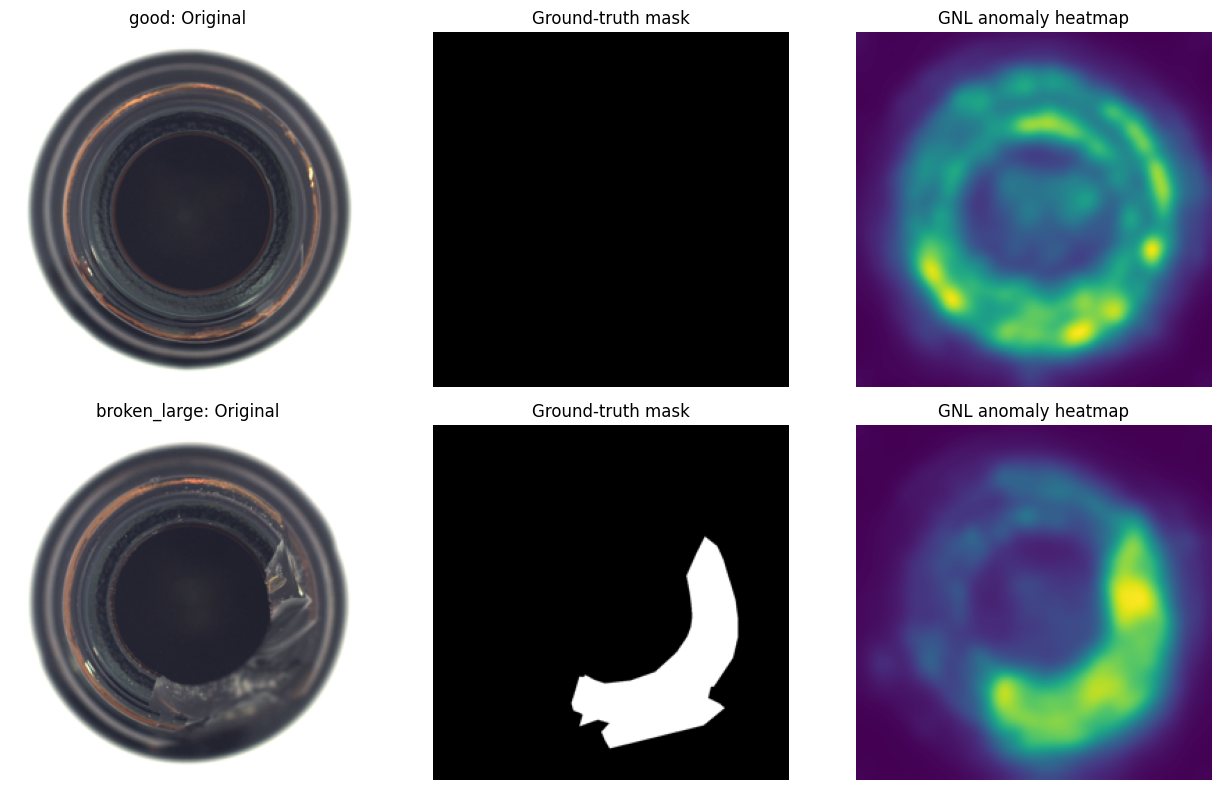

In [69]:
%cd /content/ADShift-GNL-working

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from dataset import MVTecDataset, get_data_transforms

root = "/content/mvtec_dataset/bottle"
map_dir = "results/bottle_id/anomaly_maps"

image_transform, mask_transform = get_data_transforms(256, 256)

dataset = MVTecDataset(
    root=root,
    transform=image_transform,
    gt_transform=mask_transform,
    phase="test"
)

examples = [
    ("012.png", "good"),
    ("000.png", "broken_large")
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for row, (filename, defect_type) in enumerate(examples):

    idx = next(
        i for i, path in enumerate(dataset.img_paths)
        if os.path.basename(path) == filename
        and dataset.types[i] == defect_type
    )

    original = Image.open(dataset.img_paths[idx]).convert("RGB").resize((256, 256))

    if dataset.gt_paths[idx] == 0:
        mask = np.zeros((256, 256))
    else:
        mask = np.array(
            Image.open(dataset.gt_paths[idx]).convert("L").resize((256, 256))
        )

    prefix = f"{idx:03d}_{defect_type}_{filename}"
    heatmap_path = os.path.join(
        map_dir, prefix.replace(".png", "_heatmap.png")
    )

    heatmap = Image.open(heatmap_path)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"{defect_type}: Original")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("Ground-truth mask")

    axes[row, 2].imshow(heatmap)
    axes[row, 2].set_title("GNL anomaly heatmap")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [70]:
%cd /content/ADShift-GNL-working

!grep -n -E "bottle|category|dataset-root|checkpoint-dir|results-dir" train_gnl_bottle.py

/content/ADShift-GNL-working
59:    print("Category: bottle")
107:    # Pretrained teacher and attention bottleneck.
123:    # Only bottleneck and decoder are optimized.
181:                # Trainable bottleneck and decoder.
276:                "category": "bottle",
304:        "--dataset-root",
305:        default="/content/mvtec_dataset/bottle"
317:        "--checkpoint-dir",
318:        default="checkpoints/bottle"
322:        "--results-dir",
323:        default="results/bottle"


In [71]:
%cd /content/ADShift-GNL-working

!sed -n '45,70p' train_gnl_bottle.py
!sed -n '255,330p' train_gnl_bottle.py

/content/ADShift-GNL-working
def main(args):

    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(args.seed)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Device:", device)
    print("Category: bottle")
    print("Dataset:", args.dataset_root)

    # Official ADShift image preprocessing.
    resize_transform = transforms.Compose([
        transforms.Resize((256, 256))
    ])

    preprocess = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=mean_train,
            log_file.flush()

            print(
                "Epoch {}/{} | Total: {:.6f} | "
                "Normal: {:.6f} | BN: {:.6f} | "
                "Decoder: {:.6f}".format(
                    epoch + 1,
                    args.epochs,
                    *averages
                )
            )

            # 

In [72]:
%cd /content/ADShift-GNL-working

from pathlib import Path

source_path = Path("train_gnl_bottle.py")
target_path = Path("train_gnl_category.py")

source = source_path.read_text()

# Replace hardcoded category references.
source = source.replace(
    'print("Category: bottle")',
    'print("Category:", args.category)'
)

source = source.replace(
    '"category": "bottle"',
    '"category": args.category'
)

source = source.replace(
    'default="/content/mvtec_dataset/bottle"',
    'default="/content/mvtec_dataset/cable"'
)

source = source.replace(
    'default="checkpoints/bottle"',
    'default="checkpoints/cable_full"'
)

source = source.replace(
    'default="results/bottle"',
    'default="results/cable_full"'
)

# Add configurable category argument.
source = source.replace(
    'parser.add_argument(\n        "--dataset-root",',
    'parser.add_argument("--category", type=str, default="cable")\n\n'
    '    parser.add_argument(\n        "--dataset-root",'
)

target_path.write_text(source)

print("Created:", target_path)

/content/ADShift-GNL-working
Created: train_gnl_category.py


In [73]:
%cd /content/ADShift-GNL-working

!python -m py_compile train_gnl_category.py

!grep -n -E "category|bottle|cable|dataset-root|checkpoint-dir|results-dir" train_gnl_category.py

/content/ADShift-GNL-working
59:    print("Category:", args.category)
107:    # Pretrained teacher and attention bottleneck.
123:    # Only bottleneck and decoder are optimized.
181:                # Trainable bottleneck and decoder.
276:                "category": args.category,
303:    parser.add_argument("--category", type=str, default="cable")
306:        "--dataset-root",
307:        default="/content/mvtec_dataset/cable"
319:        "--checkpoint-dir",
320:        default="checkpoints/cable_full"
324:        "--results-dir",
325:        default="results/cable_full"


In [74]:
%cd /content/ADShift-GNL-working

import os
from glob import glob

root = "/content/mvtec_dataset/cable"

train_images = glob(os.path.join(root, "train", "good", "*.png"))

test_good = glob(os.path.join(root, "test", "good", "*.png"))

defect_types = [
    d for d in os.listdir(os.path.join(root, "test"))
    if d != "good"
]

print("===== CABLE DATASET VERIFICATION =====")
print("Dataset exists:", os.path.isdir(root))
print("Normal training images:", len(train_images))
print("Normal test images:", len(test_good))

total_defects = 0

for defect in sorted(defect_types):
    images = glob(os.path.join(root, "test", defect, "*.png"))
    masks = glob(os.path.join(root, "ground_truth", defect, "*.png"))

    total_defects += len(images)

    print(
        defect,
        "| Images:", len(images),
        "| Masks:", len(masks),
        "| Match:", len(images) == len(masks)
    )

print("Total defective images:", total_defects)
print("Total test images:", len(test_good) + total_defects)

/content/ADShift-GNL-working
===== CABLE DATASET VERIFICATION =====
Dataset exists: True
Normal training images: 224
Normal test images: 58
bent_wire | Images: 13 | Masks: 13 | Match: True
cable_swap | Images: 12 | Masks: 12 | Match: True
combined | Images: 11 | Masks: 11 | Match: True
cut_inner_insulation | Images: 14 | Masks: 14 | Match: True
cut_outer_insulation | Images: 10 | Masks: 10 | Match: True
missing_cable | Images: 12 | Masks: 12 | Match: True
missing_wire | Images: 10 | Masks: 10 | Match: True
poke_insulation | Images: 10 | Masks: 10 | Match: True
Total defective images: 92
Total test images: 150


In [75]:
%cd /content/ADShift-GNL-working

!python train_gnl_category.py \
    --category cable \
    --dataset-root /content/mvtec_dataset/cable \
    --epochs 1 \
    --batch-size 16 \
    --max-batches 1 \
    --num-workers 2 \
    --checkpoint-dir checkpoints/cable_smoke \
    --results-dir results/cable_smoke

/content/ADShift-GNL-working
Device: cuda
Category: cable
Dataset: /content/mvtec_dataset/cable
ImageFolder classes: ['good']
Normal training images: 224
Epoch 1/1 | Total: 1.745996 | Normal: 1.871186 | BN: 0.382881 | Decoder: 0.855679
Latest checkpoint saved: checkpoints/cable_smoke/latest.pth
Peak GPU memory: 9.145 GB

Training completed.
Training log: results/cable_smoke/training_log.csv


In [76]:
%cd /content/ADShift-GNL-working

!python train_gnl_category.py \
    --category cable \
    --dataset-root /content/mvtec_dataset/cable \
    --epochs 20 \
    --batch-size 16 \
    --num-workers 2 \
    --checkpoint-dir checkpoints/cable_full \
    --results-dir results/cable_full

/content/ADShift-GNL-working
Device: cuda
Category: cable
Dataset: /content/mvtec_dataset/cable
ImageFolder classes: ['good']
Normal training images: 224
Epoch 1/20 | Total: 1.141223 | Normal: 1.261569 | BN: 0.042605 | Decoder: 0.073618
Latest checkpoint saved: checkpoints/cable_full/latest.pth
Peak GPU memory: 9.919 GB
Epoch 2/20 | Total: 0.756114 | Normal: 0.839836 | BN: 0.005204 | Decoder: 0.000026
Latest checkpoint saved: checkpoints/cable_full/latest.pth
Peak GPU memory: 9.922 GB
Epoch 3/20 | Total: 0.631958 | Normal: 0.701904 | BN: 0.004835 | Decoder: 0.000064
Latest checkpoint saved: checkpoints/cable_full/latest.pth
Peak GPU memory: 9.924 GB
Epoch 4/20 | Total: 0.544321 | Normal: 0.604495 | BN: 0.005362 | Decoder: 0.000142
Latest checkpoint saved: checkpoints/cable_full/latest.pth
Peak GPU memory: 9.924 GB
Epoch 5/20 | Total: 0.498165 | Normal: 0.553173 | BN: 0.005983 | Decoder: 0.000213
Latest checkpoint saved: checkpoints/cable_full/latest.pth
Peak GPU memory: 9.924 GB
Epoch 

In [77]:
%cd /content/ADShift-GNL-working

import os
import torch

path = "checkpoints/cable_full/latest.pth"
ckpt = torch.load(path, map_location="cpu", weights_only=False)

print("Checkpoint exists:", os.path.exists(path))
print("Checkpoint size (MB):", round(os.path.getsize(path) / (1024**2), 2))
print("Category:", ckpt.get("category"))
print("Epoch:", ckpt.get("epoch"))
print("Final loss:", ckpt.get("loss"))
print("Bottleneck tensors:", len(ckpt["bn"]))
print("Decoder tensors:", len(ckpt["decoder"]))
print("Training log exists:", os.path.exists("results/cable_full/training_log.csv"))

/content/ADShift-GNL-working
Checkpoint exists: True
Checkpoint size (MB): 991.56
Category: cable
Epoch: 20
Final loss: 0.3127743772097996
Bottleneck tensors: 84
Decoder tensors: 252
Training log exists: True


In [78]:
%cd /content/ADShift-GNL-working

!grep -nE "ArgumentParser|add_argument|bottle|dataset_root|checkpoint|results|MVTecDataset|roc_auc|anomaly_maps" infer_gnl_bottle_id.py

/content/ADShift-GNL-working
11:from sklearn.metrics import roc_auc_score
16:from dataset import MVTecDataset, get_data_transforms
39:    parser = argparse.ArgumentParser()
41:    parser.add_argument(
43:        default="/content/mvtec_dataset/bottle"
46:    parser.add_argument(
47:        "--checkpoint",
48:        default="checkpoints/bottle_full/latest.pth"
51:    parser.add_argument(
53:        default="results/bottle_id"
64:    map_dir = os.path.join(args.output_dir, "anomaly_maps")
68:    print("Dataset:", args.dataset_root)
69:    print("Checkpoint:", args.checkpoint)
74:    test_dataset = MVTecDataset(
75:        root=args.dataset_root,
94:    checkpoint = torch.load(
95:        args.checkpoint,
100:    bn.load_state_dict(checkpoint["bn"], strict=True)
101:    decoder.load_state_dict(checkpoint["decoder"], strict=True)
107:    print("Loaded checkpoint epoch:", checkpoint["epoch"])
193:    image_auroc = roc_auc_score(image_labels, image_scores)
196:    pixel_auroc = roc_auc_scor

In [79]:
%cd /content/ADShift-GNL-working

import shutil

shutil.copy(
    "infer_gnl_bottle_id.py",
    "infer_gnl_category_id.py"
)

print("Created infer_gnl_category_id.py")

/content/ADShift-GNL-working
Created infer_gnl_category_id.py


In [81]:
%cd /content/ADShift-GNL-working

!sed -n '1,125p' infer_gnl_category_id.py

/content/ADShift-GNL-working

import os
import csv
import argparse

import numpy as np
import torch
import torch.nn.functional as F

from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score
from PIL import Image

from resnet import wide_resnet50_2
from de_resnet import de_wide_resnet50_2
from dataset import MVTecDataset, get_data_transforms


def calculate_anomaly_map(teacher_features, student_features, out_size=256):
    anomaly_map = np.zeros((out_size, out_size), dtype=np.float32)

    for teacher, student in zip(teacher_features, student_features):
        distance = 1 - F.cosine_similarity(teacher, student)
        distance = distance.unsqueeze(1)

        distance = F.interpolate(
            distance,
            size=(out_size, out_size),
            mode="bilinear",
            align_corners=True
        )

        anomaly_map += distance[0, 0].cpu().numpy()

    return gaussian_filter(anomaly_map, sigma=4)


def main():
    parser = argparse.Argumen

In [82]:
%cd /content/ADShift-GNL-working

!sed -n '126,260p' infer_gnl_category_id.py

/content/ADShift-GNL-working
            anomaly_map = calculate_anomaly_map(
                teacher_features,
                student_features,
                out_size=256
            )

            label = int(labels.item())
            defect_type = defect_types[0]
            filename = os.path.basename(
                test_dataset.img_paths[index]
            )

            image_score = float(np.max(anomaly_map))

            image_labels.append(label)
            image_scores.append(image_score)

            mask = masks[0, 0].cpu().numpy()
            mask_binary = (mask > 0.5).astype(np.uint8)

            pixel_labels.extend(mask_binary.reshape(-1).tolist())
            pixel_scores.extend(anomaly_map.reshape(-1).tolist())

            map_name = (
                "{:03d}_{}_{}".format(index, defect_type, filename)
            )

            np.save(
                os.path.join(map_dir, map_name.replace(".png", ".npy")),
                anomaly_map
            )

        

In [84]:
%cd /content/ADShift-GNL-working

from pathlib import Path

p = Path("infer_gnl_category_id.py")

print("File exists:", p.exists())
print("File size:", p.stat().st_size if p.exists() else "Missing")
print("Contains calculate_anomaly_map:",
      "def calculate_anomaly_map" in p.read_text())
print("Contains main function:",
      "def main():" in p.read_text())

/content/ADShift-GNL-working
File exists: True
File size: 6655
Contains calculate_anomaly_map: True
Contains main function: True


In [85]:
%cd /content/ADShift-GNL-working

from pathlib import Path

p = Path("infer_gnl_category_id.py")
source = p.read_text()

start = source.index("def main():")
end = source.index('\n\nif __name__ == "__main__":')

new_main = r'''
def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--category", required=True)
    parser.add_argument("--dataset-root", required=True)
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument("--output-dir", required=True)
    args = parser.parse_args()

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    os.makedirs(args.output_dir, exist_ok=True)
    map_dir = os.path.join(args.output_dir, "anomaly_maps")
    os.makedirs(map_dir, exist_ok=True)

    print("Device:", device)
    print("Category:", args.category)
    print("Dataset:", args.dataset_root)
    print("Checkpoint:", args.checkpoint)

    image_transform, mask_transform = get_data_transforms(256, 256)

    test_dataset = MVTecDataset(
        root=args.dataset_root,
        transform=image_transform,
        gt_transform=mask_transform,
        phase="test"
    )

    test_loader = torch.utils.data.DataLoader(
        test_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=2
    )

    print("Test images:", len(test_dataset))

    encoder, bn = wide_resnet50_2(pretrained=True)
    decoder = de_wide_resnet50_2(pretrained=False)

    checkpoint = torch.load(
        args.checkpoint,
        map_location="cpu",
        weights_only=False
    )

    if checkpoint.get("category") != args.category:
        raise ValueError(
            "Checkpoint category mismatch: expected {}, got {}".format(
                args.category, checkpoint.get("category")
            )
        )

    bn.load_state_dict(checkpoint["bn"], strict=True)
    decoder.load_state_dict(checkpoint["decoder"], strict=True)

    encoder = encoder.to(device).eval()
    bn = bn.to(device).eval()
    decoder = decoder.to(device).eval()

    print("Loaded checkpoint epoch:", checkpoint["epoch"])

    image_labels, image_scores = [], []
    pixel_labels, pixel_scores = [], []
    records = []

    with torch.no_grad():
        for index, batch in enumerate(test_loader):
            images, masks, labels, defect_types = batch
            images = images.to(device)

            teacher_features = encoder(images)
            student_features = decoder(bn(teacher_features))

            anomaly_map = calculate_anomaly_map(
                teacher_features, student_features, out_size=256
            )

            label = int(labels.item())
            defect_type = defect_types[0]
            filename = os.path.basename(test_dataset.img_paths[index])
            image_score = float(np.max(anomaly_map))

            image_labels.append(label)
            image_scores.append(image_score)

            mask = masks[0, 0].cpu().numpy()
            mask_binary = (mask > 0.5).astype(np.uint8)

            pixel_labels.extend(mask_binary.reshape(-1).tolist())
            pixel_scores.extend(anomaly_map.reshape(-1).tolist())

            map_name = "{:03d}_{}_{}".format(
                index, defect_type, filename
            )

            np.save(
                os.path.join(map_dir, map_name.replace(".png", ".npy")),
                anomaly_map
            )

            map_min, map_max = anomaly_map.min(), anomaly_map.max()
            normalized_map = (
                (anomaly_map - map_min) / (map_max - map_min + 1e-8)
            )

            heatmap = Image.fromarray(
                (normalized_map * 255).astype(np.uint8)
            )
            heatmap.save(
                os.path.join(
                    map_dir, map_name.replace(".png", "_heatmap.png")
                )
            )

            records.append({
                "filename": filename,
                "defect_type": defect_type,
                "label": label,
                "image_score": image_score
            })

            if (index + 1) % 10 == 0 or index + 1 == len(test_dataset):
                print("Processed: {}/{}".format(
                    index + 1, len(test_dataset)
                ))

    image_auroc = roc_auc_score(image_labels, image_scores)
    pixel_auroc = roc_auc_score(pixel_labels, pixel_scores)

    with open(os.path.join(args.output_dir, "image_scores.csv"), "w",
              newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=[
                "filename", "defect_type", "label", "image_score"
            ]
        )
        writer.writeheader()
        writer.writerows(records)

    with open(os.path.join(args.output_dir, "evaluation_summary.txt"), "w") as f:
        f.write("GNL {} ID Evaluation\n".format(args.category))
        f.write("========================\n")
        f.write("Checkpoint epoch: {}\n".format(checkpoint["epoch"]))
        f.write("Test images: {}\n".format(len(test_dataset)))
        f.write("Normal images: {}\n".format(image_labels.count(0)))
        f.write("Anomalous images: {}\n".format(image_labels.count(1)))
        f.write("Image-level AUROC: {:.6f}\n".format(image_auroc))
        f.write("Pixel-level AUROC: {:.6f}\n".format(pixel_auroc))

    print("\n===== EVALUATION RESULTS =====")
    print("Category:", args.category)
    print("Test images:", len(test_dataset))
    print("Normal:", image_labels.count(0))
    print("Anomalous:", image_labels.count(1))
    print("Image-level AUROC:", round(image_auroc, 6))
    print("Pixel-level AUROC:", round(pixel_auroc, 6))
    print("Results saved:", args.output_dir)
'''

p.write_text(source[:start] + new_main + source[end:])

print("Updated inference script successfully.")
!python -m py_compile infer_gnl_category_id.py
print("Syntax check passed.")

/content/ADShift-GNL-working
Updated inference script successfully.
Syntax check passed.


In [86]:
%cd /content/ADShift-GNL-working

!python infer_gnl_category_id.py \
    --category cable \
    --dataset-root /content/mvtec_dataset/cable \
    --checkpoint checkpoints/cable_full/latest.pth \
    --output-dir results/cable_id

/content/ADShift-GNL-working
Device: cuda
Category: cable
Dataset: /content/mvtec_dataset/cable
Checkpoint: checkpoints/cable_full/latest.pth
Test images: 150
Loaded checkpoint epoch: 20
Processed: 10/150
Processed: 20/150
Processed: 30/150
Processed: 40/150
Processed: 50/150
Processed: 60/150
Processed: 70/150
Processed: 80/150
Processed: 90/150
Processed: 100/150
Processed: 110/150
Processed: 120/150
Processed: 130/150
Processed: 140/150
Processed: 150/150

===== EVALUATION RESULTS =====
Category: cable
Test images: 150
Normal: 58
Anomalous: 92
Image-level AUROC: 0.959708
Pixel-level AUROC: 0.981416
Results saved: results/cable_id


In [1]:
%cd /content/GNL-Grounded-RD4AD-MVTecAD

!grep -RniE "AUPRO|compute_aupro|PRO curve|per.region.overlap" evaluation

[Errno 2] No such file or directory: '/content/GNL-Grounded-RD4AD-MVTecAD'
/content
grep: evaluation: No such file or directory


In [2]:
import os

print("Folders in /content:")
for item in sorted(os.listdir("/content")):
    path = os.path.join("/content", item)
    if os.path.isdir(path):
        print(item)

Folders in /content:
.config
sample_data


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

root = "/content/drive/MyDrive"

keywords = [
    "ADShift-GNL-working",
    "bottle_full",
    "cable_full",
    "bottle_id",
    "cable_id"
]

print("Searching Google Drive for saved GNL experiments...\n")

for current, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]

    for name in dirs + files:
        if any(k.lower() in name.lower() for k in keywords):
            print(os.path.join(current, name))

Searching Google Drive for saved GNL experiments...



In [5]:
import os

root = "/content/drive/MyDrive"

print("Google Drive folders and files:")
for item in os.listdir(root):
    print(item)

Google Drive folders and files:
Colab Notebooks
Classroom
dec
FIC 101.pdf
FIC 101.gdoc
History_of_Computers (3).gdoc
History_of_Computers (2).gdoc
History_of_Computers (1).gdoc
History_of_Computers.gdoc
YouCut_20231201_233647118.mp4
KOTA NAGA ABHINAY Assignment-3 (1).pdf
KOTA NAGA ABHINAY Assignment-3.pdf
Photo from ~abhi😉 (3)
Photo from ~abhi😉 (2)
23110010968_copy (1).pdf
nithin_k_sec103_Assignment-1.pdf
NAGA ABHINAY KOTA Assignment-1.pdf
KOTA NAGA ABHINAY ASSIGNMENT-2.pdf
1707236171850.jpg
1707236171854.jpg
23110010968_copy.pdf
Photo from ~abhi😉 (1)
idea.pdf
AP23110010999.docx.pdf
DOC.pdf
PLASTIC WATER BOTTLES__ALPHA.pdf
Entrepreneurial Mindset.pdf
PDFGallery_20240216_103024.pdf
AP23110010999_CLA 2.pdf
AP23110010999_CLA 3.pdf
AP23110010999 CLA_2.pdf
Photo from ~abhi😉
6.pdf
9.pdf
AP23110010999_CLA-2.pdf
AP23110010999_ABHINAY_CLA3.pdf
UHE CLA 2 (1).pdf
UHE CLA 2.pdf
sanction letter .pdf
Lec 7-Functions.gdoc
DOC-20240927-WA0092..pdf
sum.cpp.pdf
discrete cla.pdf
Adobe Scan 07-Nov-2024.pd

In [6]:
import os

for folder in ["dec", "Colab Notebooks"]:
    path = f"/content/drive/MyDrive/{folder}"

    print("\n---", folder, "---")

    if os.path.isdir(path):
        for root, dirs, files in os.walk(path):
            level = root.replace(path, "").count(os.sep)
            if level > 2:
                dirs[:] = []
                continue

            print("  " * level + os.path.basename(root) + "/")

            for file in files[:20]:
                print("  " * (level + 1) + file)


--- dec ---
dec/

--- Colab Notebooks ---
Colab Notebooks/
  GNL Baseline.ipynb
  exp6-7.ipynb
  exp-6-71.ipynb
  exp-10 (2).ipynb
  Untitled0.ipynb
  exp-10 (1).ipynb
  exp-10.ipynb
  Untitled1.ipynb
  DL_LAB2.ipynb
  Untitled2.ipynb
  Untitled3.ipynb
  Untitled5.ipynb
  Untitled4.ipynb
  Untitled6.ipynb
  Untitled7.ipynb
  Untitled8.ipynb
  Untitled9.ipynb
  Untitled10.ipynb
  Untitled11.ipynb
  GNL-Grounded RD4AD – Member 3 PCA Implementation (MVTec AD).ipynb


In [7]:
import json
import os

path = "/content/drive/MyDrive/Colab Notebooks/GNL Baseline.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Notebook exists:", os.path.exists(path))
print("Total cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    outputs = cell.get("outputs", [])

    if source.strip():
        print("\n" + "=" * 50)
        print("CELL:", i, "| TYPE:", cell["cell_type"])
        print(source[:500].replace("\n", " "))

    if outputs:
        print("Stored outputs:", len(outputs))
        for output in outputs:
            text = "".join(output.get("text", []))
            if text:
                print(text[:500])

Notebook exists: True
Total cells: 96

CELL: 0 | TYPE: code
import torch  print("PyTorch:", torch.__version__) print("CUDA available:", torch.cuda.is_available())  if torch.cuda.is_available():     print("GPU:", torch.cuda.get_device_name(0))     print("CUDA version:", torch.version.cuda)
Stored outputs: 1
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


CELL: 1 | TYPE: code
import torch  a = torch.randn(1024, 1024, device="cuda") b = torch.randn(1024, 1024, device="cuda")  c = torch.matmul(a, b) torch.cuda.synchronize()  print("GPU computation: SUCCESS") print("Output shape:", c.shape) print("GPU:", torch.cuda.get_device_name(0)) print("GPU memory allocated:",       round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")
Stored outputs: 1
GPU computation: SUCCESS
Output shape: torch.Size([1024, 1024])
GPU: Tesla T4
GPU memory allocated: 20.12 MB


CELL: 2 | TYPE: code
%cd /content  !if [ -d GNL-Grounded-RD4AD-MVTecAD/.git ]; then echo "Repository already 

In [8]:
%cd /content

!git clone https://github.com/abhinayk04/GNL-Grounded-RD4AD-MVTecAD.git

!git clone https://github.com/mala-lab/ADShift.git ADShift-official

print("\nProject repositories restored.")

/content
Cloning into 'GNL-Grounded-RD4AD-MVTecAD'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 23), reused 50 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 20.24 KiB | 1.45 MiB/s, done.
Resolving deltas: 100% (23/23), done.
Cloning into 'ADShift-official'...
remote: Enumerating objects: 78, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 78 (delta 27), reused 22 (delta 22), pack-reused 44 (from 1)
Receiving objects: 100% (78/78), 33.56 KiB | 3.73 MiB/s, done.
Resolving deltas: 100% (39/39), done.

Project repositories restored.


In [9]:
%cd /content/GNL-Grounded-RD4AD-MVTecAD

print("===== PROJECT FILES =====")
!find . -maxdepth 4 -type f | sort

print("\n===== EVALUATION METRICS =====")
!grep -RniE "AUPRO|compute_aupro|PRO curve|pixel.*AUROC" . --include="*.py"

/content/GNL-Grounded-RD4AD-MVTecAD
===== PROJECT FILES =====
./ADShift/.gitkeep
./checkpoints/.gitkeep
./checkpoints/gnl/.gitkeep
./checkpoints/rd4ad/.gitkeep
./datasets/.gitkeep
./documentation/dataset_report/.gitkeep
./documentation/dataset_report/mvtec_verification.md
./documentation/final_report/.gitkeep
./documentation/.gitkeep
./documentation/implementation_notes/.gitkeep
./documentation/implementation_notes/member3_integration_handoff.md
./documentation/implementation_notes/member3_pca_implementation.md
./evaluation/compare_official_aupro.py
./evaluation/__init__.py
./evaluation/metrics.py
./evaluation/mvtec_loader.py
./evaluation/test_metrics.py
./experiments/.gitkeep
./experiments/gnl/.gitkeep
./experiments/pca/.gitkeep
./experiments/rd4ad/.gitkeep
./.git/config
./.git/description
./.git/HEAD
./.git/hooks/applypatch-msg.sample
./.git/hooks/commit-msg.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/post-update.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/p

In [10]:
%cd /content/GNL-Grounded-RD4AD-MVTecAD

print("===== RUNNING SHARED METRIC TESTS =====")
!python -m evaluation.test_metrics

print("\n===== METRIC FUNCTION SIGNATURES =====")
!sed -n '1,245p' evaluation/metrics.py

print("\n===== MVTec LOADER INTERFACE =====")
!sed -n '1,240p' evaluation/mvtec_loader.py

/content/GNL-Grounded-RD4AD-MVTecAD
===== RUNNING SHARED METRIC TESTS =====
PASSED: Image AUROC
PASSED: Empty image inputs
PASSED: Mismatched image lengths
PASSED: NaN image scores
PASSED: Invalid image labels
PASSED: Missing defective image class
PASSED: Pixel AUROC
PASSED: Pixel AUROC with no defect pixels
PASSED: Multiple images and defect regions
Multiple-region AUPRO: 1.0
PASSED: Imperfect prediction map
Imperfect AUPRO: 0.15
PASSED: AUPRO without defect regions
PASSED: AUPRO with NaN scores
PASSED: Invalid AUPRO integration limit
image_auroc : 1.0
pixel_auroc : 1.0
aupro : 1.0

ALL EXPANDED METRIC TESTS PASSED

===== METRIC FUNCTION SIGNATURES =====

import numpy as np
from sklearn.metrics import roc_auc_score
from scipy.ndimage import label as connected_components


def _to_numpy(data):
    """Convert NumPy arrays or PyTorch tensors to NumPy."""
    if hasattr(data, "detach"):
        data = data.detach().cpu().numpy()
    return np.asarray(data)


def _prepare_maps(masks, anoma

In [11]:
from pathlib import Path

print("===== DATASET LOCATIONS =====")
for p in [
    Path("/content/mvtec_dataset"),
    Path("/content/datasets"),
    Path("/content/drive/MyDrive"),
]:
    print(f"\n{p} — exists: {p.exists()}")
    if p.exists():
        if p.name == "MyDrive":
            for item in sorted(p.iterdir()):
                print(" ", item.name, "[DIR]" if item.is_dir() else "[FILE]")
        else:
            print(" ", [x.name for x in list(p.iterdir())[:20]])

print("\n===== SEARCH FOR SAVED GNL ARTIFACTS IN DRIVE =====")
drive = Path("/content/drive/MyDrive")
if drive.exists():
    for pattern in ["*.pth", "*.pt", "*.npy", "image_scores.csv", "evaluation_summary.txt"]:
        matches = list(drive.rglob(pattern))
        print(f"\n{pattern}: {len(matches)} found")
        for item in matches[:15]:
            print(" ", item)

===== DATASET LOCATIONS =====

/content/mvtec_dataset — exists: False

/content/datasets — exists: False

/content/drive/MyDrive — exists: True
  1-s2.0-S0957417422008065-main_copy.pdf [FILE]
  10th_Marksheet_Kota_Naga_Abhinay.pdf.pdf [FILE]
  12th_Marksheet_Kota_Naga_Abhinay.pdf.pdf [FILE]
  13.05.2026 AN seating arrangement.pdf [FILE]
  1707236171850.jpg [FILE]
  1707236171854.jpg [FILE]
  17607906099485466262370507255875.jpg [FILE]
  1_AI_Intro.pdf [FILE]
  23110010968_copy (1).pdf [FILE]
  23110010968_copy.pdf [FILE]
  6.pdf [FILE]
  8_Weeks_Weekly_Report.pdf [FILE]
  9.pdf [FILE]
  ABHI AADHARpdf (1).pdf [FILE]
  ABHI AADHARpdf.pdf [FILE]
  AP23110010999 ASSIGNMENT-1.pdf [FILE]
  AP23110010999 CLA_2.pdf [FILE]
  AP23110010999 DAA.pdf [FILE]
  AP23110010999 Mental_health.xlsm [FILE]
  AP23110010999.docx.pdf [FILE]
  AP23110010999_2 [FILE]
  AP23110010999_2023_24147_2_UROP_CLA.pdf [FILE]
  AP23110010999_3.docx [FILE]
  AP23110010999_4.docx [FILE]
  AP23110010999_ABHINAY_CLA3.pdf [FI

In [12]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/GNL Baseline.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("Notebook found:", notebook_path.exists())
print("Total cells:", len(notebook["cells"]))
print("\n===== SCRIPT CREATION CELLS =====")

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])
    if "%%writefile" in source:
        print(f"\n--- Cell {i} ---")
        print("\n".join(source.splitlines()[:5]))

Notebook found: True
Total cells: 96

===== SCRIPT CREATION CELLS =====

--- Cell 46 ---

%%writefile /content/ADShift-GNL-working/train_gnl_bottle.py

import os
import csv

--- Cell 63 ---
%%writefile /content/ADShift-GNL-working/infer_gnl_bottle_id.py

import os
import csv
import argparse


In [13]:
import json

notebook_path = "/content/drive/MyDrive/Colab Notebooks/GNL Baseline.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in [46, 63, 71, 82]:
    cell = nb["cells"][i]
    print("\n" + "=" * 80)
    print(f"CELL {i} | {cell['cell_type']}")
    print("=" * 80)
    print("".join(cell["source"]))


CELL 46 | code

%%writefile /content/ADShift-GNL-working/train_gnl_bottle.py

import os
import csv
import argparse
import random
import numpy as np
import torch

from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

from resnet import wide_resnet50_2
from de_resnet import de_wide_resnet50_2
from dataset import AugMixDatasetMVTec, mean_train, std_train


def loss_function(a, b):
    cosine = torch.nn.CosineSimilarity(dim=1)
    loss = 0.0

    for i in range(len(a)):
        loss += torch.mean(
            1 - cosine(
                a[i].flatten(1),
                b[i].flatten(1)
            )
        )

    return loss


def loss_function_last(a, b):
    cosine = torch.nn.CosineSimilarity(dim=1)

    # Preserve official ADShift implementation: index 0.
    return torch.mean(
        1 - cosine(
            a[0].flatten(1),
            b[0].flatten(1)
        )
    )


def main(args):

    random.seed(args.seed)
    n

In [14]:
from pathlib import Path
import shutil

source = Path("/content/ADShift-official")
target = Path("/content/ADShift-GNL-working")

if not source.exists():
    raise FileNotFoundError("Official ADShift repository is missing.")

if target.exists():
    print("Working copy already exists. Leaving it unchanged.")
else:
    shutil.copytree(source, target)
    print("Created working copy:", target)

print("\nRequired source files:")
for name in ["resnet.py", "de_resnet.py", "dataset.py", "test.py"]:
    p = target / name
    print(name, "FOUND" if p.exists() else "MISSING")

Created working copy: /content/ADShift-GNL-working

Required source files:
resnet.py FOUND
de_resnet.py FOUND
dataset.py FOUND
test.py FOUND


In [15]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/GNL Baseline.ipynb"
)
work_dir = Path("/content/ADShift-GNL-working")

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

scripts = {
    46: "train_gnl_bottle.py",
    63: "infer_gnl_bottle_id.py",
}

for cell_index, filename in scripts.items():
    source = "".join(nb["cells"][cell_index]["source"])

    # Remove the notebook-only %%writefile directive.
    lines = source.splitlines()
    if lines and lines[0].startswith("%%writefile"):
        source = "\n".join(lines[1:]).lstrip("\n")

    destination = work_dir / filename
    destination.write_text(source, encoding="utf-8")
    print("Restored:", destination)

print("\n===== SYNTAX CHECK =====")
import py_compile

for filename in scripts.values():
    py_compile.compile(
        str(work_dir / filename),
        doraise=True
    )
    print("PASSED:", filename)

Restored: /content/ADShift-GNL-working/train_gnl_bottle.py
Restored: /content/ADShift-GNL-working/infer_gnl_bottle_id.py

===== SYNTAX CHECK =====


PyCompileError:   File "/content/ADShift-GNL-working/train_gnl_bottle.py", line 2
    %%writefile /content/ADShift-GNL-working/train_gnl_bottle.py
    ^
SyntaxError: invalid syntax


In [16]:
from pathlib import Path
import py_compile

work_dir = Path("/content/ADShift-GNL-working")

for filename in [
    "train_gnl_bottle.py",
    "infer_gnl_bottle_id.py"
]:
    path = work_dir / filename
    source = path.read_text(encoding="utf-8")

    lines = source.splitlines()

    # Remove notebook cell magic wherever it appears.
    lines = [
        line for line in lines
        if not line.strip().startswith("%%writefile")
    ]

    # Remove leading blank lines.
    source = "\n".join(lines).lstrip() + "\n"
    path.write_text(source, encoding="utf-8")

    py_compile.compile(str(path), doraise=True)
    print("SYNTAX PASSED:", filename)

print("\nBoth bottle scripts are restored and syntactically valid.")

SYNTAX PASSED: train_gnl_bottle.py
SYNTAX PASSED: infer_gnl_bottle_id.py

Both bottle scripts are restored and syntactically valid.


In [17]:
import json

notebook_path = "/content/drive/MyDrive/Colab Notebooks/GNL Baseline.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in range(70, 84):
    cell = nb["cells"][i]
    source = "".join(cell.get("source", []))

    print(f"\n===== CELL {i} | {cell['cell_type']} =====")
    print("\n".join(source.splitlines()[:12]))

    if cell.get("outputs"):
        for output in cell["outputs"]:
            text = "".join(output.get("text", []))
            if text:
                print("OUTPUT:", text[:500])


===== CELL 70 | code =====
%cd /content/ADShift-GNL-working

!sed -n '45,70p' train_gnl_bottle.py
!sed -n '255,330p' train_gnl_bottle.py
OUTPUT: /content/ADShift-GNL-working
def main(args):

    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(args.seed)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Device:", device)
    print("Category: bottle")
    print("Dataset:", args.dataset_root)

    # Official ADShift image preprocessing.
    resize_transform = transforms.Compose([
    

===== CELL 71 | code =====
%cd /content/ADShift-GNL-working

from pathlib import Path

source_path = Path("train_gnl_bottle.py")
target_path = Path("train_gnl_category.py")

source = source_path.read_text()

# Replace hardcoded category references.
source = source.replace(
    'print("Category: bottle")',
OUTPUT: /content/ADShift-GNL-working
Created:

In [ ]:
import json
from pathlib import Path
import py_compile

work = Path("/content/ADShift-GNL-working")
notebook = Path("/content/drive/MyDrive/Colab Notebooks/GNL Baseline.ipynb")

with open(notebook, "r", encoding="utf-8") as f:
    nb = json.load(f)

# 1. Restore category training script using cell 71 transformation.
source = (work / "train_gnl_bottle.py").read_text()

source = source.replace(
    'print("Category: bottle")',
    'print("Category:", args.category)'
)
source = source.replace(
    '"category": "bottle"',
    '"category": args.category'
)
source = source.replace(
    'default="/content/mvtec_dataset/bottle"',
    'default="/content/mvtec_dataset/cable"'
)
source = source.replace(
    'default="checkpoints/bottle"',
    'default="checkpoints/cable_full"'
)
source = source.replace(
    'default="results/bottle"',
    'default="results/cable_full"'
)
source = source.replace(
    'parser.add_argument(\n        "--dataset-root",',
    'parser.add_argument("--category", type=str, default="cable")\n\n'
    '    parser.add_argument(\n        "--dataset-root",'
)

(work / "train_gnl_category.py").write_text(source)

# 2. Restore generic inference script from cell 82.
source = "".join(nb["cells"][78]["source"])
# Cell 78 is a copy command, so start from the recovered bottle script.
source = (work / "infer_gnl_bottle_id.py").read_text()
source = source.replace(
    'default="/content/mvtec_dataset/bottle"',
    'default="/content/mvtec_dataset/cable"'
)
source = source.replace(
    'default="checkpoints/bottle_full/latest.pth"',
    'default="checkpoints/cable_full/latest.pth"'
)
source = source.replace(
    'default="results/bottle_id"',
    'default="results/cable_id"'
)

# Apply the exact main-function replacement recorded in cell 82.
cell82 = "".join(nb["cells"][82]["source"])
start = cell82.index("new_main = r'''") + len("new_main = r'''")
end = cell82.index("'''", start)
new_main = cell82[start:end]

main_start = source.index("def main():")
main_end = source.index('\n\nif __name__ == "__main__":')
source = source[:main_start] + new_main + source[main_end:]

(work / "infer_gnl_category_id.py").write_text(source)

# 3. Syntax validation.
for filename in [
    "train_gnl_bottle.py",
    "infer_gnl_bottle_id.py",
    "train_gnl_category.py",
    "infer_gnl_category_id.py"
]:
    py_compile.compile(str(work / filename), doraise=True)
    print("SYNTAX PASSED:", filename)

print("\nAll four scripts restored.")